# İnsan Sanal İkizi: Gerçek Bağlantıom Verisiyle Kişiye Özel Tüm-Beyin Modeli
### *Human Virtual Twins: Subject-Specific Whole-Brain Models from Real Connectome Data*

**Hedef dergi:** Journal of Computational Bioengineering and Clinical Medicine (JCBCM)
**Çalışma türü:** Araştırma makalesi + derleme bileşeni (melez)
**Çalışma ortamı:** Google Colab (Python 3)

---

## Bu notebook ne yapıyor?

Bu çalışmada bir **insan sanal ikizi** (human virtual twin) kuruyoruz. Burada "ikiz" kelimesi, bir kişinin **beyninin bilgisayarda çalışan, kişiye özel bir modeli** anlamına geliyor. Görüntü işleme yapmıyoruz. Görüntülerden önceden çıkarılmış **gerçek bağlantı matrislerini** kullanıp beyni **diferansiyel denklemlerle simüle ediyoruz**.

Çalışmanın üç sorusu var:

| # | Soru | Bölüm |
|---|------|-------|
| S1 | Kişinin yapısal bağlantıomu (DTI) üzerine kurulan dinamik model, o kişinin dinlenim-hali fMRI aktivitesini yeniden üretebiliyor mu? | 5–6 |
| S2 | İkiz gerçekten **o kişiye mi özgü**? Kişinin kendi ikizi, başkalarının ikizlerinden daha mı iyi uyuyor? | 7 |
| S3 | İkiz üzerinde **sanal müdahale** (sanal lezyon) yapınca hangi bölgeler ağı en çok bozuyor? | 8 |

Derleme bileşeni olarak da **OpenAlex** veri tabanından gerçek yayın verisi çekip alanın küresel ve Türkiye'deki durumunu nicel olarak inceliyoruz (Bölüm 9).

## Veri

**Human Connectome Project (HCP)** kapsamında toplanmış 7 sağlıklı yetişkinin verisini kullanıyoruz. Veri, açık kaynak `neurolib` kütüphanesiyle birlikte dağıtılıyor (Cakan ve ark., 2021). Her denek için şu matrisler var:
- **Yapısal bağlantı (SC):** DTI traktografisinden, 80 kortikal bölge (AAL2 atlası).
- **Lif uzunluğu matrisi (Dmat):** bölgeler arası lif uzunlukları.
- **Dinlenim-hali BOLD zaman serisi:** 80 bölge × 1200 zaman noktası (TR = 0,72 s, yaklaşık 14,4 dakika).

Ek olarak ikinci bağımsız bir kohort (`gw`, 5 denek) yalnızca yapı-işlev bağlantısının tekrarlanabilirliğini göstermek için kullanılıyor.

## Şekiller hakkında

Her şekil **iki dilde** üretiliyor:
- Türkçe sürümü `sekiller/tr/` klasörüne,
- İngilizce sürümü `sekiller/en/` klasörüne kaydediliyor.

Hepsi **300 dpi JPEG** formatında; JCBCM bu formatı istiyor. İngilizce sürümler doğrudan makaleye girebilir.

## İçindekiler
0. Kurulum ve ayarlar
1. Gerçek verinin yüklenmesi
2. Verinin keşifsel analizi (görselleştirmeler)
3. Ampirik yapı–işlev ilişkisi ve bireysel parmak izi
4. Model: Hopf (Stuart–Landau) osilatör ağı
5. İkizin kişiye kalibrasyonu
6. Çapraz doğrulama: ikiz görmediği veriyi öngörebiliyor mu?
7. Kişiye özgülük testi
8. Sanal müdahale: sanal lezyon deneyi
9. Literatür bileşeni: OpenAlex bibliyometrisi ve Türkiye
10. Sonuç tablosu ve şekillerin indirilmesi

## 0. Kurulum ve ayarlar

Colab'da `neurolib` hazır gelmez, o yüzden ilk hücre onu kurar. Kurulum yaklaşık 1 dakika sürer. Diğer paketler (numpy, scipy, pandas, matplotlib, seaborn, networkx, requests) Colab'da zaten yüklüdür.

> **Not:** Kurulumdan sonra Colab bazen "Restart session" uyarısı verir. Uyarı gelirse oturumu yeniden başlatın ve hücreleri baştan çalıştırın.

In [1]:
# neurolib kütüphanesini kur (Colab'da yoksa). Gerçek HCP verisi bu paketin içinde geliyor.
import importlib, subprocess, sys
if importlib.util.find_spec("neurolib") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "neurolib"], check=True)
    print("neurolib kuruldu.")
else:
    print("neurolib zaten kurulu.")

neurolib kuruldu.


In [2]:
# ---- Temel kütüphaneler ----
import os, time, json, warnings, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D
import seaborn as sns
import networkx as nx
from scipy.signal import butter, filtfilt, welch
from scipy.stats import ks_2samp, wilcoxon, spearmanr, pearsonr

# neurolib: gerçek veriyi yüklemek ve AAL2 atlas bilgisi için
from neurolib.utils.loadData import Dataset
from neurolib.utils import atlases

warnings.filterwarnings("ignore")
import logging; logging.getLogger().setLevel(logging.ERROR)  # neurolib'in bilgi mesajlarını sustur

# ---- Tekrarlanabilirlik: tüm rastgele süreçler sabit tohumla başlar ----
ANA_TOHUM = 2026
np.random.seed(ANA_TOHUM)

print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", mpl.__version__)

numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0


### Görselleştirme ayarları ve iki dilli şekil yardımcısı

Her şekli bir fonksiyon olarak yazıyoruz: `ciz(dil)`. Bu fonksiyon `dil="tr"` ya da `dil="en"` alır ve metinleri ona göre seçer. Ardından `iki_dilli(...)` yardımcısı fonksiyonu iki kez çağırır, iki şekli de kaydeder ve ekranda gösterir.

Renk seçimleri şöyle:
- **Kategorik renkler** (denekler, koşullar) için renk-körü dostu, doğrulanmış sabit bir palet kullanıyoruz. Renkler her zaman aynı sırayla atanır.
- **Büyüklük** (ör. bağlantı gücü) tek tonlu bir skalayla gösterilir.
- **İşaretli değerler** (ör. pozitif/negatif korelasyon) iki kutuplu, ortası nötr bir skalayla gösterilir.

In [3]:
# ---- Klasörler ----
SEKIL_DIR = "sekiller"
for d in ["tr", "en"]:
    os.makedirs(os.path.join(SEKIL_DIR, d), exist_ok=True)
os.makedirs("ciktilar", exist_ok=True)   # tablolar (CSV) buraya

# ---- Renk paleti (renk-körü dostu, sabit sıra) ----
KAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
MAVI, TURUNCU, YESIL, SARI, PEMBE, KOYU_YESIL, MOR, KIRMIZI = KAT
GRI = "#8a8985"
SEQ = "Blues"      # büyüklük (tek ton)
DIV = "RdBu_r"     # işaretli değer (iki kutup, ortası nötr)

# ---- Genel matplotlib stili: ince işaretler, sade eksenler ----
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300,
    "font.family": "DejaVu Sans", "font.size": 9,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#52514e", "axes.linewidth": 0.8,
    "axes.grid": False, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "legend.frameon": False, "lines.linewidth": 1.6,
})

def iki_dilli(ciz, ad, goster=True):
    # ciz(dil) bir matplotlib Figure döndürmeli. Türkçe ve İngilizce sürümler
    # 300 dpi JPEG olarak kaydedilir ve (istenirse) ekranda gösterilir.
    for dil in ["tr", "en"]:
        fig = ciz(dil)
        yol = os.path.join(SEKIL_DIR, dil, f"{ad}.jpg")
        fig.savefig(yol, dpi=300, bbox_inches="tight", facecolor="white",
                    pil_kwargs={"quality": 95})
        if goster:
            plt.show()
        plt.close(fig)
    print(f"Kaydedildi -> {SEKIL_DIR}/tr/{ad}.jpg  ve  {SEKIL_DIR}/en/{ad}.jpg")

def T(dil, tr, en):
    # Dile göre metin seçen küçük yardımcı.
    return tr if dil == "tr" else en

## 1. Gerçek verinin yüklenmesi

`Dataset("hcp")` komutu HCP deneklerinin verisini yükler:
- `ds.Cmats`: denek başına yapısal bağlantı (SC) matrisleri. En büyük değere bölünerek 0–1 aralığına normalize edilmişlerdir.
- `ds.Dmats`: lif uzunlukları (mm).
- `ds.BOLDs`: dinlenim-hali BOLD zaman serileri.

Atlas olarak AAL2 kullanılıyor. Alt-kortikal bölgeler çıkarılmış durumda, geriye **80 kortikal bölge** kalıyor. Bölgelerin adları ve beyindeki MNI koordinatları da atlastan geliyor; koordinatları beyin haritası çizimlerinde kullanacağız.

In [4]:
ds = Dataset("hcp")           # ana kohort: Human Connectome Project
ds_gw = Dataset("gw")         # ikinci kohort (yalnızca tekrarlanabilirlik için)

SC   = [np.array(c, dtype=float) for c in ds.Cmats]     # yapısal bağlantı
DM   = [np.array(d, dtype=float) for d in ds.Dmats]     # lif uzunlukları (mm)
BOLD = [np.array(b, dtype=float) for b in ds.BOLDs]     # BOLD zaman serileri

# Denek kimlikleri: neurolib verileri klasörden alfabetik olmayan bir sırayla okur.
# Bu yüzden kimlikleri, verinin yüklendiği sırayla aynı sözlükten alıyoruz;
# böylece her kimlik kesinlikle kendi matrisleriyle eşleşir.
DENEKLER = list(ds.data["subjects"].keys())
NS = len(SC)                   # denek sayısı
N = SC[0].shape[0]             # bölge sayısı
TR = 0.72                      # HCP dinlenim fMRI tekrarlama süresi (saniye)
T_NOKTA = BOLD[0].shape[1]

atlas = atlases.AutomatedAnatomicalParcellation2()
BOLGE = list(atlas.names())                 # 80 bölge adı
XYZ = np.array(atlas.coords())              # MNI koordinatları (80 x 3)
HEMI = np.array([0 if b.endswith("_L") else 1 for b in BOLGE])   # 0 = sol, 1 = sağ

print(f"Denek sayısı: {NS} | Bölge sayısı: {N} | Zaman noktası: {T_NOKTA} "
      f"(= {T_NOKTA*TR/60:.1f} dakika)")
print("Denekler:", DENEKLER)
print("İlk 6 bölge:", BOLGE[:6])
print("İkinci kohort (gw):", len(ds_gw.Cmats), "denek,", ds_gw.BOLDs[0].shape[1], "zaman noktası")

Denek sayısı: 7 | Bölge sayısı: 80 | Zaman noktası: 1200 (= 14.4 dakika)
Denekler: ['211619', '101309', '131217', '213522', '102816', '377451', '102311']
İlk 6 bölge: ['Precentral_L', 'Precentral_R', 'Frontal_Sup_2_L', 'Frontal_Sup_2_R', 'Frontal_Mid_2_L', 'Frontal_Mid_2_R']
İkinci kohort (gw): 5 denek, 355 zaman noktası


In [5]:
# Her deneğin verisinin kısa özeti (tablo)
iu = np.triu_indices(N, 1)          # üst üçgen indeksleri (köşegen hariç)
ozet = []
for s in range(NS):
    w = SC[s][iu]
    ozet.append({
        "Denek": DENEKLER[s],
        "SC yoğunluğu (%)": 100 * np.mean(w > 0),
        "Ortalama SC ağırlığı": w[w > 0].mean(),
        "Ortalama lif uzunluğu (mm)": DM[s][iu][w > 0].mean(),
        "BOLD süresi (dk)": BOLD[s].shape[1] * TR / 60,
    })
ozet = pd.DataFrame(ozet).round(3)
ozet.to_csv("ciktilar/tablo1_veri_ozeti.csv", index=False)
ozet

,Denek,SC yoğunluğu (%),Ortalama SC ağırlığı,Ortalama lif uzunluğu (mm),BOLD süresi (dk)
0,211619,100.0,0.025,130.352,14.4
1,101309,100.0,0.021,133.623,14.4
2,131217,100.0,0.023,124.095,14.4
3,213522,100.0,0.023,134.707,14.4
4,102816,100.0,0.024,126.194,14.4
5,377451,100.0,0.023,126.342,14.4
6,102311,100.0,0.022,135.410,14.4


## 2. Verinin keşifsel analizi

Modele geçmeden önce veriye bakalım. Bu bölümde şunları görselleştiriyoruz:
1. Yapısal bağlantı, lif uzunluğu ve fonksiyonel bağlantı matrisleri (bir örnek denek).
2. Ham BOLD sinyali ve tüm bölgelerin "halı grafiği" (carpet plot).
3. Bağlantıomun beyin üzerindeki yerleşimi.
4. Bağlantı ağırlıklarının dağılımı.
5. BOLD sinyalinin frekans içeriği.

### 2.1 Ön işleme: bant geçiren filtre

Dinlenim-hali fMRI analizlerinde sinyal genellikle dar bir frekans bandına süzülür. Biz Deco ve ark. (2017) ile uyumlu olarak **0,04–0,07 Hz** bandını kullanıyoruz. Bu bant gri madde sinyalinin en bilgilendirici olduğu bölgedir. Fonksiyonel bağlantı (FC), süzülmüş sinyaller arasındaki **Pearson korelasyonu** olarak hesaplanıyor.

In [6]:
F_ALT, F_UST = 0.04, 0.07                       # bant sınırları (Hz)
_b, _a = butter(2, [F_ALT / (0.5 / TR), F_UST / (0.5 / TR)], btype="band")

def suz(x):
    # Her bölgenin ortalamasını çıkar, sonra 0,04-0,07 Hz bandına süz.
    x = x - x.mean(axis=-1, keepdims=True)
    return filtfilt(_b, _a, x, axis=-1)

def fc_hesapla(x):
    # Fonksiyonel bağlantı: bölgeler arası Pearson korelasyon matrisi.
    return np.corrcoef(x)

def ust(m):
    # Bir matrisin üst üçgenini vektör olarak döndür (köşegen hariç).
    return m[iu]

BOLD_F = [suz(b) for b in BOLD]                # süzülmüş BOLD
FC_EMP = [fc_hesapla(b) for b in BOLD_F]       # ampirik FC (tam süre)
ORNEK = 0                                      # örnek denek indeksi
print("Ampirik FC hesaplandı. Örnek denek:", DENEKLER[ORNEK])

Ampirik FC hesaplandı. Örnek denek: 211619


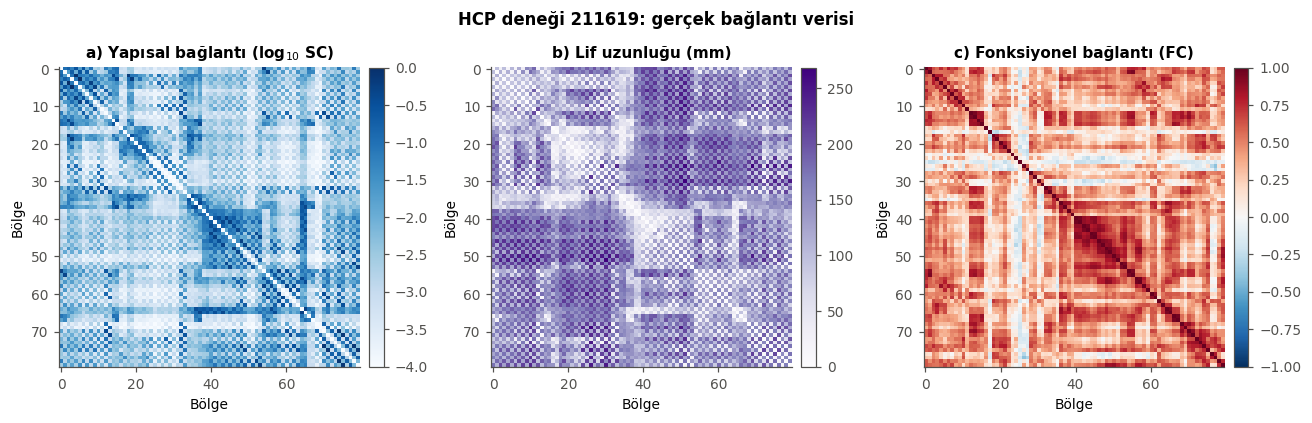

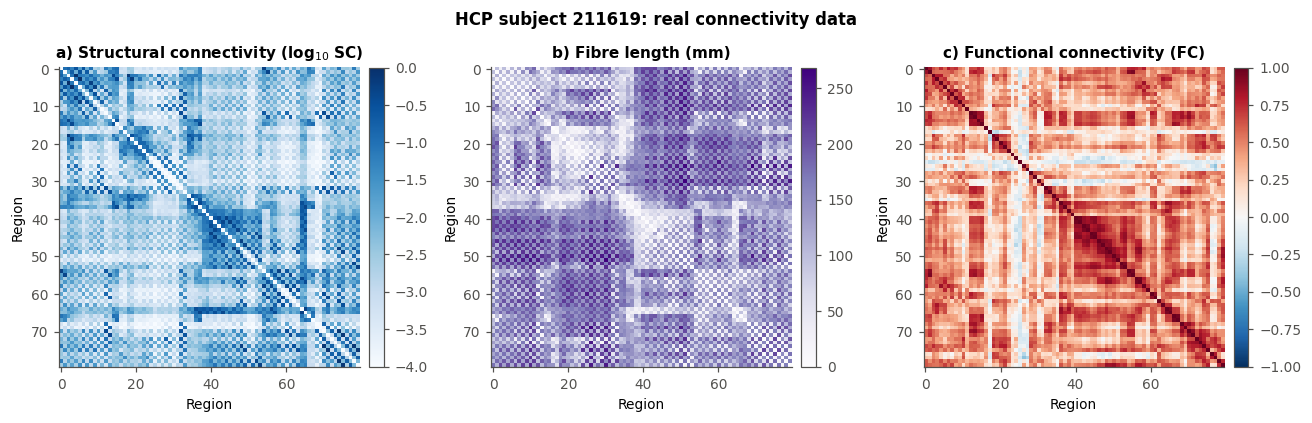

Kaydedildi -> sekiller/tr/sekil01_matrisler.jpg  ve  sekiller/en/sekil01_matrisler.jpg


In [7]:
# ŞEKİL 1: Örnek deneğin üç matrisi yan yana
def ciz(dil):
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.8))
    sc_log = np.log10(SC[ORNEK] + 1e-4)
    im0 = ax[0].imshow(sc_log, cmap=SEQ, vmin=-4, vmax=0)
    ax[0].set_title(T(dil, "a) Yapısal bağlantı (log$_{10}$ SC)", "a) Structural connectivity (log$_{10}$ SC)"))
    im1 = ax[1].imshow(DM[ORNEK], cmap="Purples")
    ax[1].set_title(T(dil, "b) Lif uzunluğu (mm)", "b) Fibre length (mm)"))
    im2 = ax[2].imshow(FC_EMP[ORNEK], cmap=DIV, vmin=-1, vmax=1)
    ax[2].set_title(T(dil, "c) Fonksiyonel bağlantı (FC)", "c) Functional connectivity (FC)"))
    for a, im in zip(ax, [im0, im1, im2]):
        a.set_xlabel(T(dil, "Bölge", "Region")); a.set_ylabel(T(dil, "Bölge", "Region"))
        fig.colorbar(im, ax=a, fraction=0.046, pad=0.03)
    fig.suptitle(T(dil, f"HCP deneği {DENEKLER[ORNEK]}: gerçek bağlantı verisi",
                        f"HCP subject {DENEKLER[ORNEK]}: real connectivity data"), fontweight="bold")
    fig.tight_layout()
    return fig
iki_dilli(ciz, "sekil01_matrisler")

**Yorum:** SC matrisinde köşegene yakın yoğunlaşma, komşu bölgelerin daha güçlü bağlı olduğunu gösteriyor. Bölgeler sol/sağ (L/R) sırayla dizili olduğu için iki yarımküre arasındaki bağlantılar da desen olarak görünüyor. FC matrisinde ise yapısal olarak doğrudan bağlı olmayan bölgeler arasında da güçlü korelasyonlar var. Bu durum, işlevin yapıdan **doğrudan** okunamayacağını gösteriyor. Model tam bu boşluğu dinamikle doldurmaya çalışıyor.

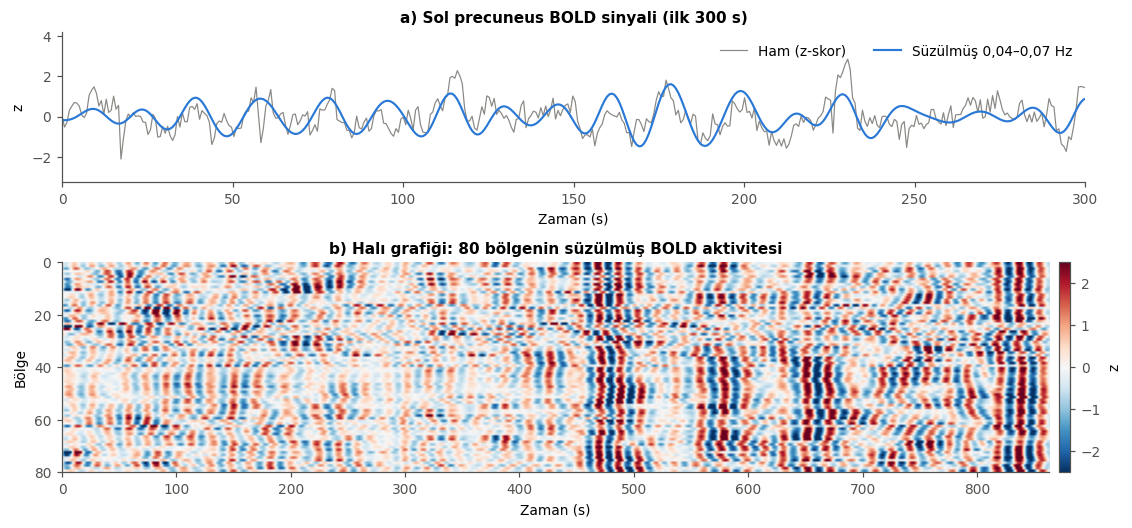

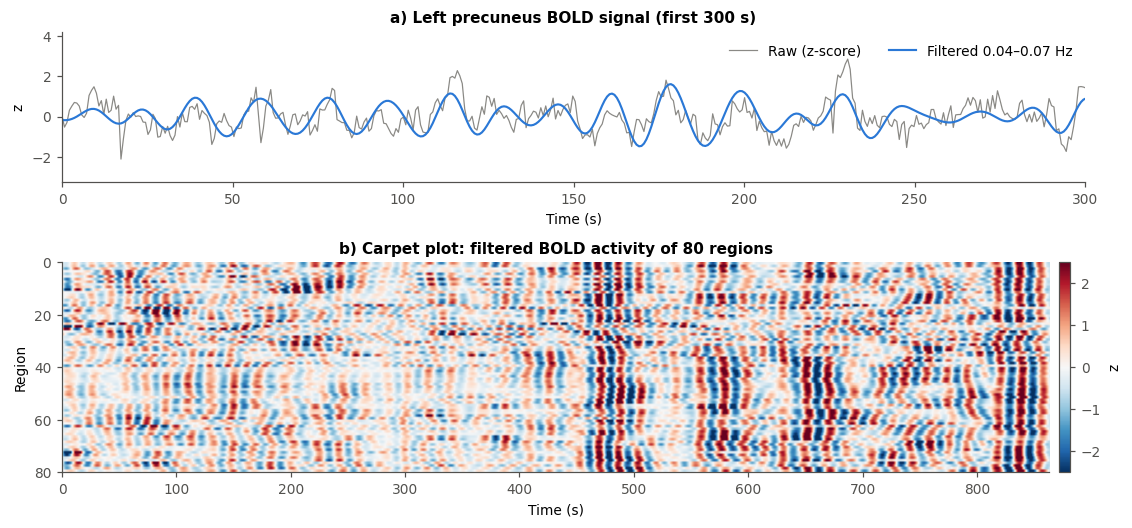

Kaydedildi -> sekiller/tr/sekil02_bold.jpg  ve  sekiller/en/sekil02_bold.jpg


In [8]:
# ŞEKİL 2: Ham ve süzülmüş BOLD sinyali + halı grafiği
def ciz(dil):
    fig = plt.figure(figsize=(12, 5.2))
    gs = fig.add_gridspec(2, 1, height_ratios=[1, 1.4], hspace=0.45)
    ax1 = fig.add_subplot(gs[0]); ax2 = fig.add_subplot(gs[1])
    t = np.arange(T_NOKTA) * TR
    k = BOLGE.index("Precuneus_L")
    ham = (BOLD[ORNEK][k] - BOLD[ORNEK][k].mean()) / BOLD[ORNEK][k].std()
    sz = BOLD_F[ORNEK][k] / BOLD_F[ORNEK][k].std()
    ax1.plot(t, ham, color=GRI, lw=0.8, label=T(dil, "Ham (z-skor)", "Raw (z-score)"))
    ax1.plot(t, sz, color=MAVI, lw=1.4, label=T(dil, "Süzülmüş 0,04–0,07 Hz", "Filtered 0.04–0.07 Hz"))
    ax1.set_xlim(0, 300); ax1.set_xlabel(T(dil, "Zaman (s)", "Time (s)")); ax1.set_ylabel("z")
    ax1.set_title(T(dil, "a) Sol precuneus BOLD sinyali (ilk 300 s)", "a) Left precuneus BOLD signal (first 300 s)"))
    ax1.legend(loc="upper right", ncol=2)
    z = (BOLD_F[ORNEK] - BOLD_F[ORNEK].mean(1, keepdims=True)) / BOLD_F[ORNEK].std(1, keepdims=True)
    im = ax2.imshow(z, aspect="auto", cmap=DIV, vmin=-2.5, vmax=2.5, extent=[0, t[-1], N, 0])
    ax2.set_xlabel(T(dil, "Zaman (s)", "Time (s)")); ax2.set_ylabel(T(dil, "Bölge", "Region"))
    ax2.set_title(T(dil, "b) Halı grafiği: 80 bölgenin süzülmüş BOLD aktivitesi",
                         "b) Carpet plot: filtered BOLD activity of 80 regions"))
    fig.colorbar(im, ax=ax2, fraction=0.025, pad=0.01, label="z")
    return fig
iki_dilli(ciz, "sekil02_bold")

### 2.2 Bağlantıomu beyin üzerinde görmek

Her bölgenin MNI koordinatını kullanarak beyni üstten (aksiyel) ve yandan (sagittal) görünümde çiziyoruz. Bu çizimde:
- **Düğüm boyutu**, bölgenin toplam bağlantı gücünü (strength) gösteriyor.
- **Kenarlar**, en güçlü %3'lük yapısal bağlantıları gösteriyor.

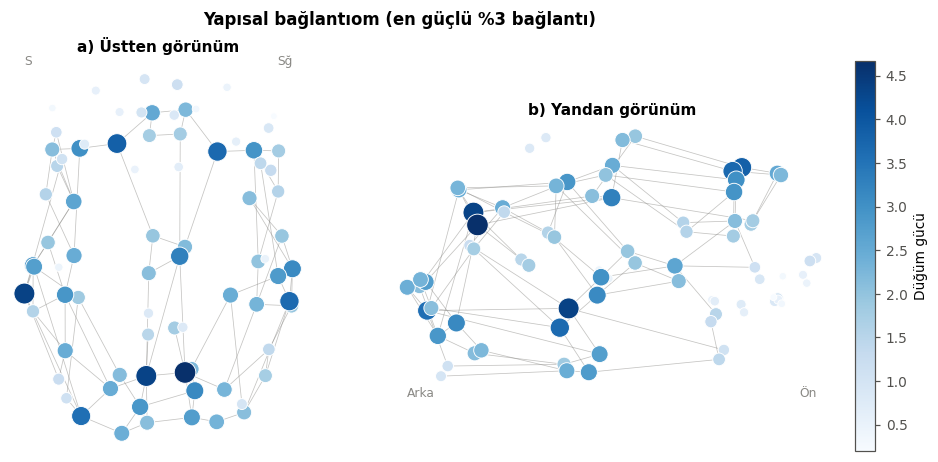

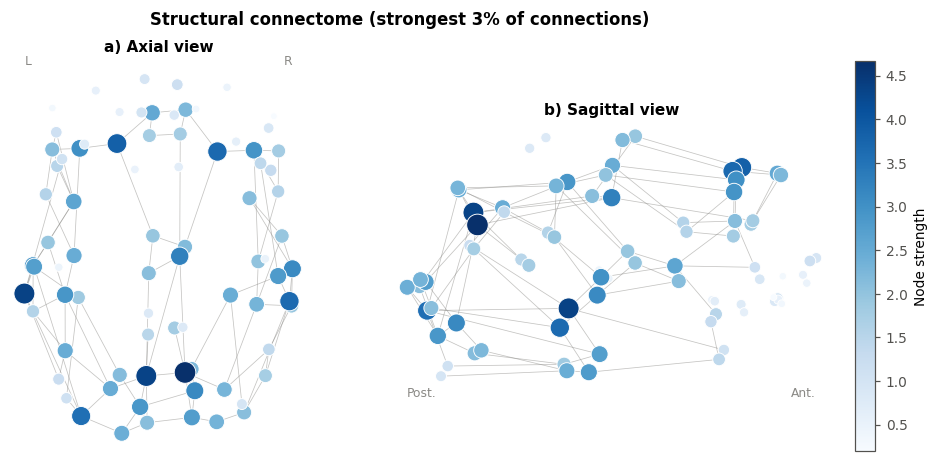

Kaydedildi -> sekiller/tr/sekil03_baglantiom_beyin.jpg  ve  sekiller/en/sekil03_baglantiom_beyin.jpg
211619 en güçlü 3 merkez (hub): ['Precuneus_R', 'Temporal_Mid_L', 'Precuneus_L']
101309 en güçlü 3 merkez (hub): ['Precuneus_R', 'Precuneus_L', 'Frontal_Sup_2_L']
131217 en güçlü 3 merkez (hub): ['Precuneus_R', 'Precuneus_L', 'Occipital_Mid_L']
213522 en güçlü 3 merkez (hub): ['Temporal_Mid_L', 'Precuneus_L', 'Precuneus_R']
102816 en güçlü 3 merkez (hub): ['Precuneus_R', 'Precuneus_L', 'Frontal_Sup_2_R']
377451 en güçlü 3 merkez (hub): ['Frontal_Sup_2_L', 'Precuneus_R', 'Precuneus_L']
102311 en güçlü 3 merkez (hub): ['Precuneus_R', 'Precuneus_L', 'Frontal_Sup_2_L']


In [9]:
def beyin_ciz(ax, deger, dil, gorunum="aksiyel", kenar_mat=None, esik_yuzde=97,
              cmap=SEQ, vmin=None, vmax=None, boyut=None, baslik=""):
    # Bölge değerlerini MNI koordinatlarında 2B olarak çizer.
    # aksiyel: x (sol-sağ) vs y (arka-ön); sagittal: y (arka-ön) vs z (alt-üst)
    i, j = (0, 1) if gorunum == "aksiyel" else (1, 2)
    P = XYZ[:, [i, j]]
    if kenar_mat is not None:
        w = kenar_mat[iu]; esik = np.percentile(w[w > 0], esik_yuzde)
        for a, b in zip(*iu):
            if kenar_mat[a, b] >= esik:
                ax.plot(P[[a, b], 0], P[[a, b], 1], color=GRI, lw=0.5, alpha=0.5, zorder=1)
    s = 30 if boyut is None else boyut
    sc = ax.scatter(P[:, 0], P[:, 1], c=deger, s=s, cmap=cmap, vmin=vmin, vmax=vmax,
                    edgecolor="white", linewidth=0.6, zorder=2)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.set_title(baslik)
    if gorunum == "aksiyel":
        ax.text(P[:, 0].min(), P[:, 1].max() + 8, T(dil, "S", "L"), fontsize=8, color=GRI)
        ax.text(P[:, 0].max(), P[:, 1].max() + 8, T(dil, "Sğ", "R"), fontsize=8, color=GRI, ha="right")
    else:
        ax.text(P[:, 0].min(), P[:, 1].min() - 10, T(dil, "Arka", "Post."), fontsize=8, color=GRI)
        ax.text(P[:, 0].max(), P[:, 1].min() - 10, T(dil, "Ön", "Ant."), fontsize=8, color=GRI, ha="right")
    return sc

GUC = [s.sum(1) for s in SC]   # düğüm gücü (strength)

def ciz(dil):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
    g = GUC[ORNEK]; boy = 20 + 180 * (g - g.min()) / (g.max() - g.min())
    beyin_ciz(ax[0], g, dil, "aksiyel", SC[ORNEK], boyut=boy,
              baslik=T(dil, "a) Üstten görünüm", "a) Axial view"))
    sc = beyin_ciz(ax[1], g, dil, "sagittal", SC[ORNEK], boyut=boy,
                   baslik=T(dil, "b) Yandan görünüm", "b) Sagittal view"))
    fig.colorbar(sc, ax=ax, fraction=0.03, pad=0.02, label=T(dil, "Düğüm gücü", "Node strength"))
    fig.suptitle(T(dil, "Yapısal bağlantıom (en güçlü %3 bağlantı)",
                        "Structural connectome (strongest 3% of connections)"), fontweight="bold")
    return fig
iki_dilli(ciz, "sekil03_baglantiom_beyin")

for s in range(NS):
    top = np.argsort(GUC[s])[::-1][:3]
    print(DENEKLER[s], "en güçlü 3 merkez (hub):", [BOLGE[k] for k in top])

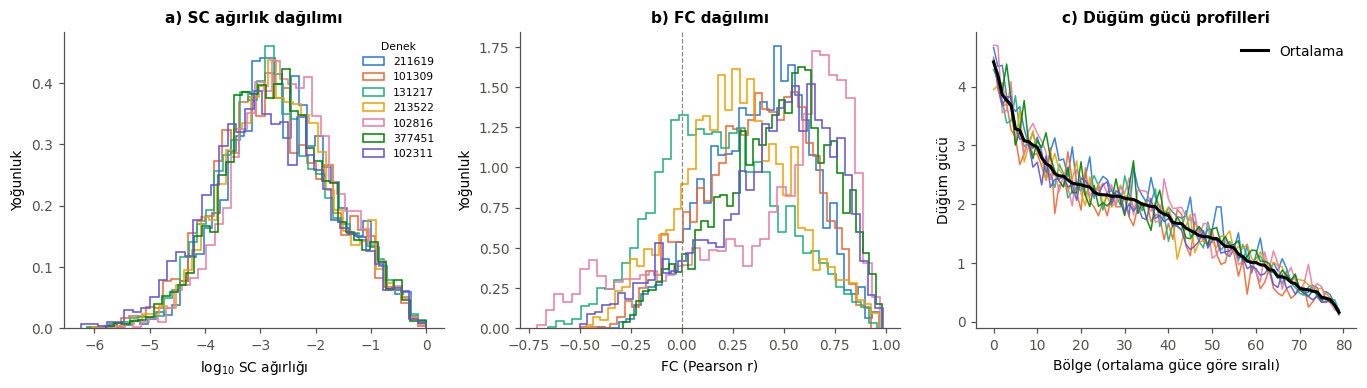

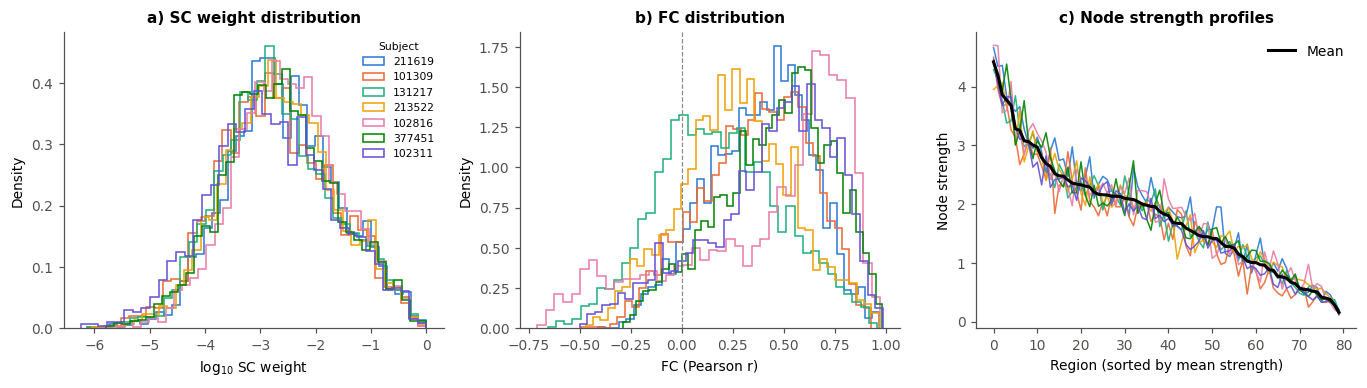

Kaydedildi -> sekiller/tr/sekil04_dagilimlar.jpg  ve  sekiller/en/sekil04_dagilimlar.jpg


In [10]:
# ŞEKİL 4: Ağırlık dağılımları ve düğüm gücü tutarlılığı (tüm denekler)
def ciz(dil):
    fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.6))
    for s in range(NS):
        w = SC[s][iu]; w = w[w > 0]
        ax[0].hist(np.log10(w), bins=40, histtype="step", color=KAT[s], lw=1.3, density=True,
                   label=DENEKLER[s])
    ax[0].set_xlabel(T(dil, "log$_{10}$ SC ağırlığı", "log$_{10}$ SC weight"))
    ax[0].set_ylabel(T(dil, "Yoğunluk", "Density"))
    ax[0].set_title(T(dil, "a) SC ağırlık dağılımı", "a) SC weight distribution"))
    ax[0].legend(fontsize=7, ncol=1, title=T(dil, "Denek", "Subject"), title_fontsize=7)
    for s in range(NS):
        ax[1].hist(ust(FC_EMP[s]), bins=40, histtype="step", color=KAT[s], lw=1.3, density=True)
    ax[1].axvline(0, color=GRI, lw=0.8, ls="--")
    ax[1].set_xlabel(T(dil, "FC (Pearson r)", "FC (Pearson r)")); ax[1].set_ylabel(T(dil, "Yoğunluk", "Density"))
    ax[1].set_title(T(dil, "b) FC dağılımı", "b) FC distribution"))
    G = np.array(GUC); sira = np.argsort(G.mean(0))[::-1]
    for s in range(NS):
        ax[2].plot(np.arange(N), G[s, sira], color=KAT[s], lw=1.0, alpha=0.9)
    ax[2].plot(np.arange(N), G.mean(0)[sira], color="black", lw=2.0,
               label=T(dil, "Ortalama", "Mean"))
    ax[2].set_xlabel(T(dil, "Bölge (ortalama güce göre sıralı)", "Region (sorted by mean strength)"))
    ax[2].set_ylabel(T(dil, "Düğüm gücü", "Node strength"))
    ax[2].set_title(T(dil, "c) Düğüm gücü profilleri", "c) Node strength profiles")); ax[2].legend()
    fig.tight_layout()
    return fig
iki_dilli(ciz, "sekil04_dagilimlar")

### 2.3 Frekans içeriği: her bölgenin kendi ritmi

Modelde her bölgenin kendine özgü bir doğal frekansı (ω) olacak. Bu frekansı uydurmuyoruz; **o kişinin gerçek verisinden ölçüyoruz**. Bunun için her bölgenin süzülmüş sinyalinin güç spektrumunda (Welch yöntemi) en yüksek tepenin frekansını alıyoruz. İkizi kişiselleştiren ilk unsur bu.

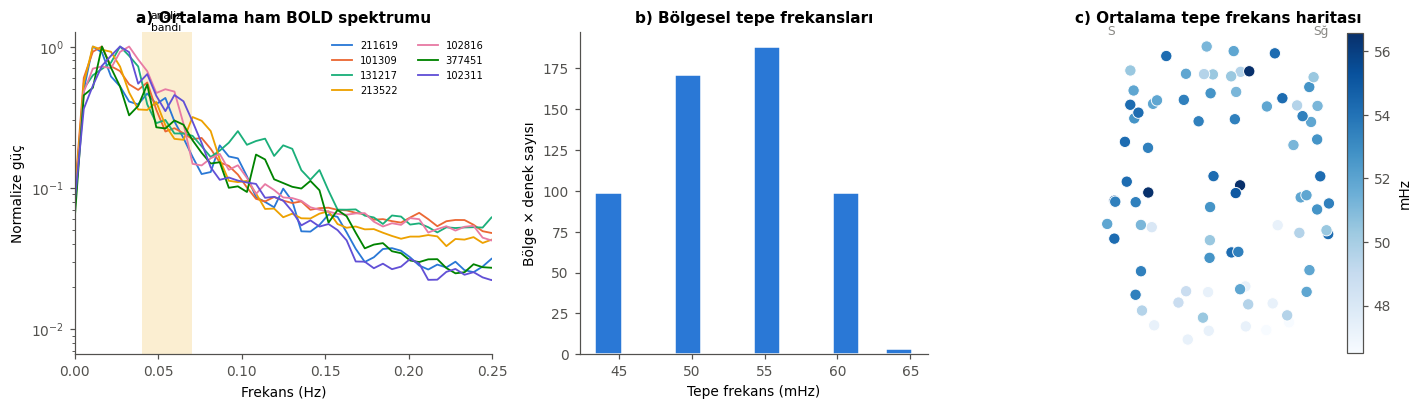

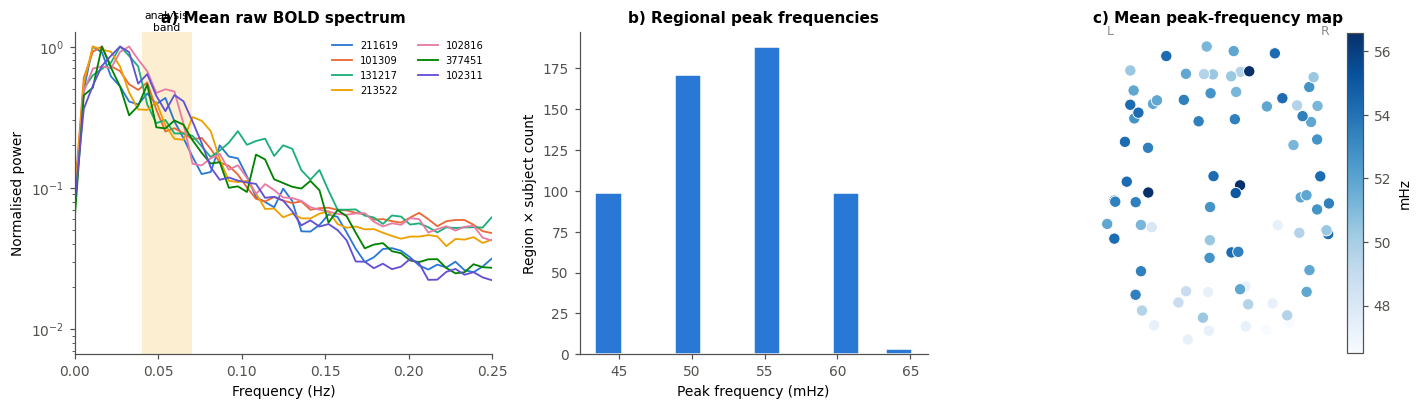

Kaydedildi -> sekiller/tr/sekil05_spektrum.jpg  ve  sekiller/en/sekil05_spektrum.jpg


In [11]:
def tepe_frekans(x):
    # Her bölgenin 0,04-0,07 Hz bandındaki spektral tepe frekansı (Hz).
    f, P = welch(x, fs=1 / TR, nperseg=256, axis=-1)
    m = (f >= F_ALT) & (f <= F_UST)
    return f[m][np.argmax(P[:, m], axis=1)]

F_TEPE = [tepe_frekans(b) for b in BOLD_F]       # denek x bölge (Hz)

def ciz(dil):
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.2, 1, 1]})
    for s in range(NS):
        f, P = welch(BOLD[s], fs=1 / TR, nperseg=256, axis=-1)
        Pm = P.mean(0); ax[0].semilogy(f, Pm / Pm.max(), color=KAT[s], lw=1.2, label=DENEKLER[s])
    ax[0].axvspan(F_ALT, F_UST, color=SARI, alpha=0.18, lw=0)
    ax[0].text((F_ALT + F_UST) / 2, 1.3, T(dil, "analiz\nbandı", "analysis\nband"), ha="center", fontsize=7)
    ax[0].set_xlim(0, 0.25); ax[0].set_xlabel(T(dil, "Frekans (Hz)", "Frequency (Hz)"))
    ax[0].set_ylabel(T(dil, "Normalize güç", "Normalised power"))
    ax[0].set_title(T(dil, "a) Ortalama ham BOLD spektrumu", "a) Mean raw BOLD spectrum"))
    ax[0].legend(fontsize=6.5, ncol=2)
    allf = np.concatenate(F_TEPE)
    ax[1].hist(allf * 1000, bins=12, color=MAVI, edgecolor="white")
    ax[1].set_xlabel(T(dil, "Tepe frekans (mHz)", "Peak frequency (mHz)"))
    ax[1].set_ylabel(T(dil, "Bölge × denek sayısı", "Region × subject count"))
    ax[1].set_title(T(dil, "b) Bölgesel tepe frekansları", "b) Regional peak frequencies"))
    sc = beyin_ciz(ax[2], np.mean(F_TEPE, 0) * 1000, dil, "aksiyel", cmap=SEQ, boyut=55,
                   baslik=T(dil, "c) Ortalama tepe frekans haritası", "c) Mean peak-frequency map"))
    fig.colorbar(sc, ax=ax[2], fraction=0.046, pad=0.02, label="mHz")
    fig.tight_layout()
    return fig
iki_dilli(ciz, "sekil05_spektrum")

## 3. Ampirik yapı–işlev ilişkisi ve bireysel parmak izi

Model kurmadan önce iki temel ölçüyü alıyoruz. Bu ölçüler daha sonra modelin başarısını kıyaslayacağımız **referans çizgileri** olacak.

1. **Doğrudan yapı–işlev uyumu:** SC ile FC'nin üst üçgenleri arasındaki korelasyon. Modelin bu değeri **aşması** gerekir; aşamazsa dinamik modele gerek yok demektir.
2. **Bireysel parmak izi:** Deneklerin SC ve FC matrisleri birbirine ne kadar benziyor? Denekler arası benzerlik çok yüksekse "kişiye özel ikiz" iddiası zorlaşır.

Ek olarak ikinci kohortta (gw, 5 denek) yapı–işlev uyumunun benzer düzeyde olup olmadığına bakıyoruz (tekrarlanabilirlik).

In [12]:
SCFC_HCP = [pearsonr(ust(SC[s]), ust(FC_EMP[s]))[0] for s in range(NS)]
SCFC_HCP_LOG = [pearsonr(np.log10(ust(SC[s]) + 1e-4), ust(FC_EMP[s]))[0] for s in range(NS)]
# İkinci kohort: neurolib'in hazır FC'leri (TR bilgisi verilmediği için süzme yapılmadı)
SCFC_GW = [pearsonr(ust(np.array(c, float)), ust(np.array(f, float)))[0]
           for c, f in zip(ds_gw.Cmats, ds_gw.FCs)]

print(f"HCP  SC–FC r (doğrusal SC): {np.mean(SCFC_HCP):.3f} ± {np.std(SCFC_HCP):.3f}")
print(f"HCP  SC–FC r (log SC)     : {np.mean(SCFC_HCP_LOG):.3f} ± {np.std(SCFC_HCP_LOG):.3f}")
print(f"GW   SC–FC r (doğrusal SC): {np.mean(SCFC_GW):.3f} ± {np.std(SCFC_GW):.3f}")

# Denekler arası benzerlik matrisleri
SIM_SC = np.array([[pearsonr(ust(SC[a]), ust(SC[b]))[0] for b in range(NS)] for a in range(NS)])
SIM_FC = np.array([[pearsonr(ust(FC_EMP[a]), ust(FC_EMP[b]))[0] for b in range(NS)] for a in range(NS)])
od = ~np.eye(NS, dtype=bool)
print(f"Denekler arası SC benzerliği: {SIM_SC[od].mean():.3f} (min {SIM_SC[od].min():.3f})")
print(f"Denekler arası FC benzerliği: {SIM_FC[od].mean():.3f} (min {SIM_FC[od].min():.3f})")

HCP  SC–FC r (doğrusal SC): 0.263 ± 0.042
HCP  SC–FC r (log SC)     : 0.347 ± 0.077
GW   SC–FC r (doğrusal SC): 0.252 ± 0.016
Denekler arası SC benzerliği: 0.974 (min 0.966)
Denekler arası FC benzerliği: 0.543 (min 0.428)


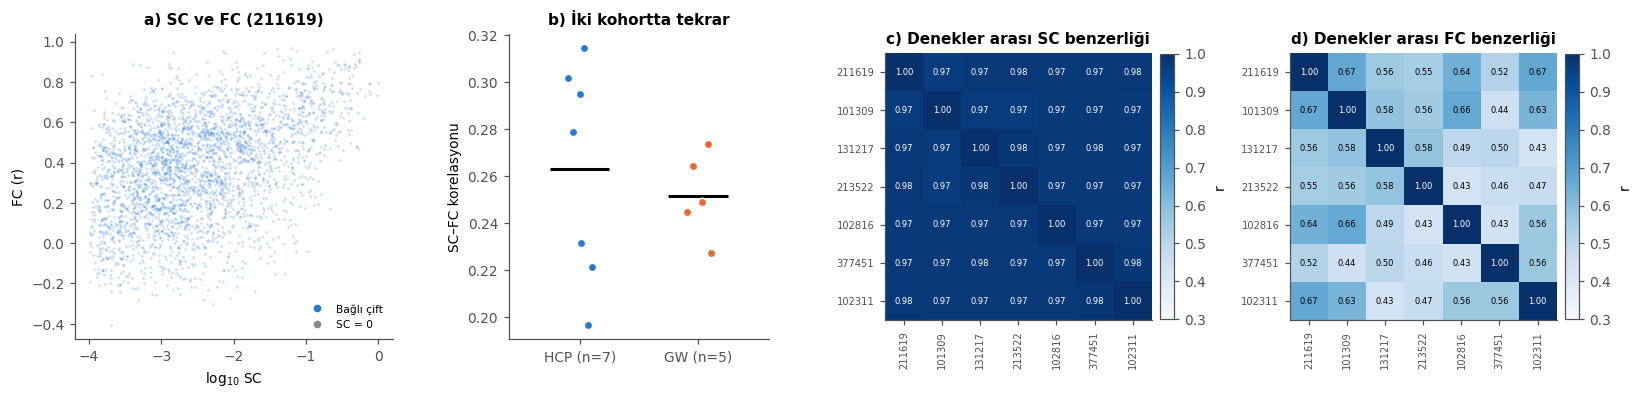

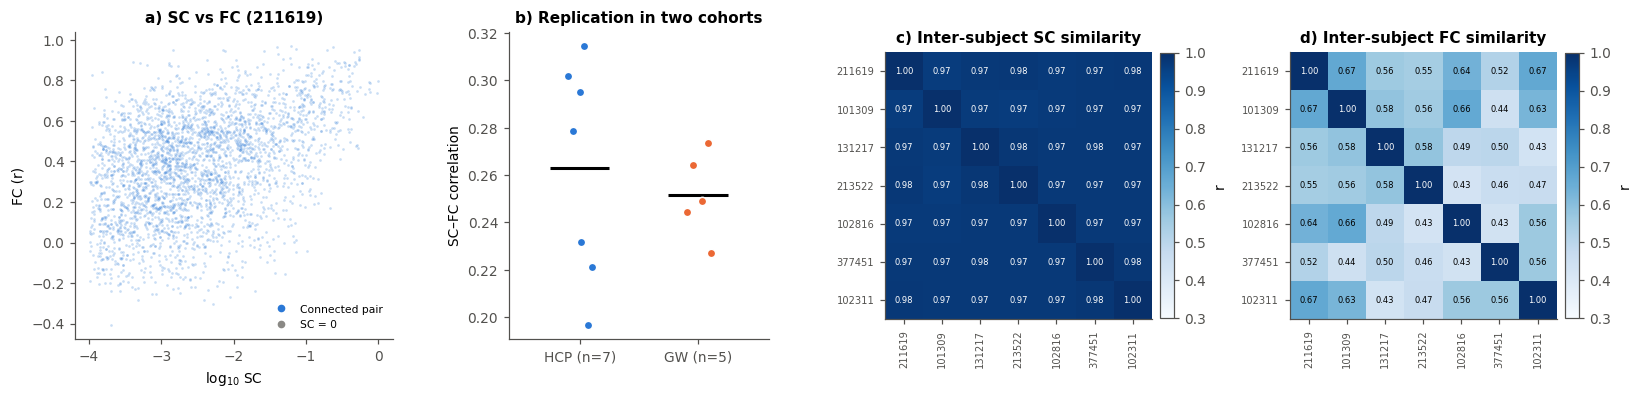

Kaydedildi -> sekiller/tr/sekil06_yapi_islev.jpg  ve  sekiller/en/sekil06_yapi_islev.jpg


In [13]:
# ŞEKİL 6: Yapı–işlev ilişkisi ve denekler arası benzerlik
def ciz(dil):
    fig, ax = plt.subplots(1, 4, figsize=(15, 3.7), gridspec_kw={"width_ratios": [1.1, 0.9, 1, 1]})
    x = np.log10(ust(SC[ORNEK]) + 1e-4); y = ust(FC_EMP[ORNEK]); m = ust(SC[ORNEK]) > 0
    ax[0].scatter(x[m], y[m], s=3, color=MAVI, alpha=0.25, lw=0)
    ax[0].scatter(x[~m], y[~m], s=3, color=GRI, alpha=0.25, lw=0)
    ax[0].set_xlabel(T(dil, "log$_{10}$ SC", "log$_{10}$ SC")); ax[0].set_ylabel("FC (r)")
    ax[0].set_title(T(dil, f"a) SC ve FC ({DENEKLER[ORNEK]})", f"a) SC vs FC ({DENEKLER[ORNEK]})"))
    ax[0].legend(handles=[Line2D([], [], marker="o", ls="", color=MAVI, ms=4, label=T(dil, "Bağlı çift", "Connected pair")),
                          Line2D([], [], marker="o", ls="", color=GRI, ms=4, label=T(dil, "SC = 0", "SC = 0"))],
                 fontsize=7, loc="lower right")
    grp = ["HCP"] * NS + ["GW"] * len(SCFC_GW); vals = SCFC_HCP + SCFC_GW
    for k, (g, v) in enumerate(zip(grp, vals)):
        xx = 0 if g == "HCP" else 1
        ax[1].scatter(xx + np.random.default_rng(k).uniform(-0.12, 0.12), v,
                      color=MAVI if g == "HCP" else TURUNCU, s=30, edgecolor="white", zorder=3)
    for xx, v in enumerate([SCFC_HCP, SCFC_GW]):
        ax[1].hlines(np.mean(v), xx - 0.25, xx + 0.25, color="black", lw=2)
    ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["HCP (n=7)", "GW (n=5)"]); ax[1].set_xlim(-0.6, 1.6)
    ax[1].set_ylabel(T(dil, "SC–FC korelasyonu", "SC–FC correlation"))
    ax[1].set_title(T(dil, "b) İki kohortta tekrar", "b) Replication in two cohorts"))
    for a, M, ttl in [(ax[2], SIM_SC, T(dil, "c) Denekler arası SC benzerliği", "c) Inter-subject SC similarity")),
                      (ax[3], SIM_FC, T(dil, "d) Denekler arası FC benzerliği", "d) Inter-subject FC similarity"))]:
        im = a.imshow(M, cmap=SEQ, vmin=0.3, vmax=1)
        a.set_xticks(range(NS)); a.set_yticks(range(NS))
        a.set_xticklabels(DENEKLER, rotation=90, fontsize=6.5); a.set_yticklabels(DENEKLER, fontsize=6.5)
        for p in range(NS):
            for q in range(NS):
                a.text(q, p, f"{M[p, q]:.2f}", ha="center", va="center", fontsize=5.5,
                       color="white" if M[p, q] > 0.8 else "black")
        a.set_title(ttl)
        fig.colorbar(im, ax=a, fraction=0.046, pad=0.03, label="r")
    fig.tight_layout()
    return fig
iki_dilli(ciz, "sekil06_yapi_islev")

**Yorum:** Yapısal bağlantı tek başına FC'nin yalnızca küçük bir kısmını açıklıyor; doğrudan korelasyon düşük-orta düzeyde. Bu değer iki bağımsız kohortta da benzer çıkıyor. Denekler arası SC benzerliği çok yüksek (insan beyinlerinin genel "kablolaması" ortak). FC benzerliği ise belirgin biçimde daha düşük. Bu durum kişiye özgü işlevsel bir imza olduğunu düşündürüyor. Bir sonraki adımda bu imzayı **yapıdan dinamik bir modelle** üretip üretemeyeceğimize bakacağız.

## 4. Model: Hopf (Stuart–Landau) osilatör ağı

### 4.1 Tek bir bölgenin denklemi

Her beyin bölgesini, Hopf çatallanmasının (bifurcation) normal formuyla tanımlanan bir osilatörle temsil ediyoruz (Deco ve ark., 2017). Bölge $j$ için karmaşık değişken $z_j = x_j + i\,y_j$:

$$
\frac{dz_j}{dt} = \underbrace{(a + i\,\omega_j)\,z_j - |z_j|^2 z_j}_{\text{yerel dinamik}} \;+\; \underbrace{G \sum_{k} C_{jk}\,(z_k - z_j)}_{\text{ağ bağlaşımı}} \;+\; \underbrace{\beta\,\eta_j(t)}_{\text{gürültü}}
$$

Terimlerin anlamı:
- $a$: **çatallanma parametresi**. $a<0$ ise bölge gürültüyle sürülen sönümlü salınımlar üretir; $a>0$ ise kendiliğinden düzenli salınır. Gerçek beyin, çatallanma noktasının hemen altında ($a=-0{,}02$) en iyi temsil ediliyor.
- $\omega_j = 2\pi f_j$: bölgenin doğal frekansı. **Kişinin kendi verisinden ölçülüyor** (Bölüm 2.3).
- $C_{jk}$: **kişinin kendi DTI yapısal bağlantı matrisi**.
- $G$: global bağlaşım gücü. Kişiye kalibre edilecek **tek serbest parametre** bu.
- $\eta_j$: Gauss beyaz gürültüsü, $\beta = 0{,}02$.

Modelin gözlenen BOLD sinyalinin karşılığı olarak $x_j(t)$ kullanılıyor. Model, ampirik veriyle aynı TR'de örnekleniyor ve aynı filtreden geçiriliyor.

### 4.2 Sayısal çözüm

Denklemleri **Euler–Maruyama** yöntemiyle çözüyoruz. Ayrıntılar:
- Adım: $dt = 0{,}06$ s. Böylece 12 adım tam olarak 1 TR'ye (0,72 s) karşılık geliyor.
- İlk 100 s ısınma süresi olarak atılıyor.
- Hesap hızı için birkaç bağımsız gürültü gerçekleşimini (tohum) **aynı anda, vektörel olarak** simüle ediyoruz. Her tohum, aynı ikizin farklı bir "çalıştırması" gibi düşünülebilir.

In [14]:
A_PAR, BETA, DT = -0.02, 0.02, 0.06
ALT_ORNEK = int(round(TR / DT))            # 12 adım = 1 TR
ISINMA_S = 100.0                           # saniye

def hopf_simule(C, G, omega, n_tohum=6, tohum=0, n_nokta=T_NOKTA, a=A_PAR, beta=BETA):
    # Hopf ağını simüle eder.
    # C: (N,N) yapısal bağlantı | G: bağlaşım | omega: (N,) açısal frekans (rad/s)
    # Dönüş: (n_tohum, N, n_nokta) boyutunda x(t) dizisi, TR aralığıyla örneklenmiş.
    rng = np.random.default_rng(tohum)
    n = C.shape[0]
    x = 0.1 * rng.standard_normal((n, n_tohum)); y = 0.1 * rng.standard_normal((n, n_tohum))
    w = np.asarray(omega)[:, None]; derece = C.sum(1)[:, None]
    isinma = int(ISINMA_S / DT); toplam = isinma + n_nokta * ALT_ORNEK
    cikti = np.empty((n_nokta, n, n_tohum)); k = 0
    sq = np.sqrt(DT) * beta
    for t in range(toplam):
        r2 = x * x + y * y
        dx = (a - r2) * x - w * y + G * (C @ x - derece * x)
        dy = (a - r2) * y + w * x + G * (C @ y - derece * y)
        x = x + DT * dx + sq * rng.standard_normal((n, n_tohum))
        y = y + DT * dy + sq * rng.standard_normal((n, n_tohum))
        if t >= isinma and (t - isinma) % ALT_ORNEK == 0:
            cikti[k] = x; k += 1
            if k == n_nokta: break
    return np.transpose(cikti, (2, 1, 0))

def sim_fc(C, G, omega, n_tohum=6, tohum=0, n_nokta=T_NOKTA):
    # Simülasyonu yapar, ampirik veriyle aynı filtreyi uygular,
    # tohumlar üzerinden ortalama FC döndürür.
    X = hopf_simule(C, G, omega, n_tohum, tohum, n_nokta)
    fcs = [fc_hesapla(suz(X[s])) for s in range(X.shape[0])]
    return np.mean(fcs, axis=0), X

t0 = time.time(); _ = hopf_simule(SC[0], 0.5, 2 * np.pi * F_TEPE[0], n_tohum=6)
print(f"Bir simülasyon (6 tohum, {T_NOKTA*TR/60:.1f} dk beyin aktivitesi): {time.time()-t0:.2f} s")

Bir simülasyon (6 tohum, 14.4 dk beyin aktivitesi): 3.38 s


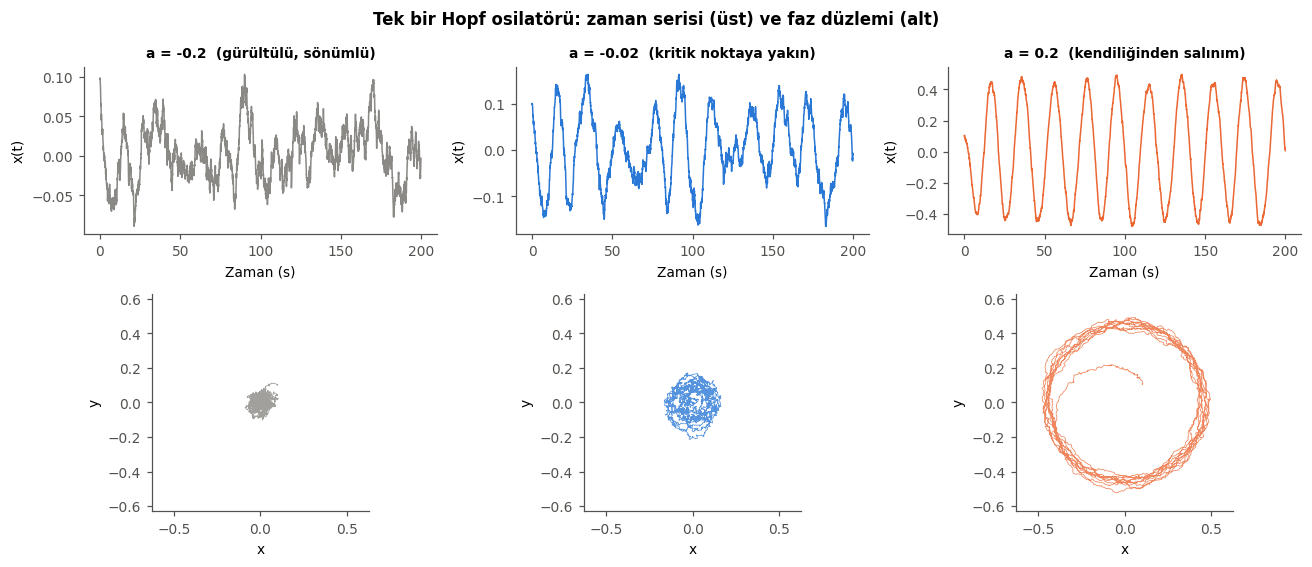

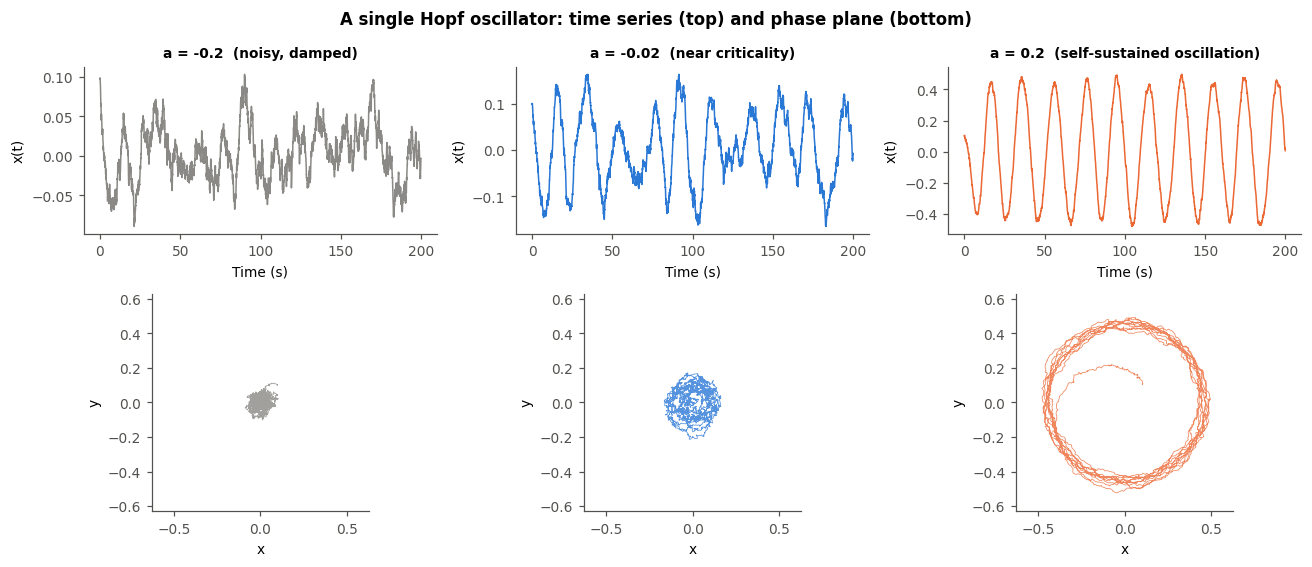

Kaydedildi -> sekiller/tr/sekil07_tek_dugum.jpg  ve  sekiller/en/sekil07_tek_dugum.jpg


In [15]:
# ŞEKİL 7: Tek bir bölgenin davranışı - çatallanma parametresi a'nın etkisi
def tek_dugum(a, sure=200, tohum=1):
    rng = np.random.default_rng(tohum); x = y = 0.1; w = 2 * np.pi * 0.05
    adim = int(sure / DT); X = np.empty(adim); Y = np.empty(adim)
    for t in range(adim):
        r2 = x * x + y * y
        x, y = (x + DT * ((a - r2) * x - w * y) + np.sqrt(DT) * BETA * rng.standard_normal(),
                y + DT * ((a - r2) * y + w * x) + np.sqrt(DT) * BETA * rng.standard_normal())
        X[t] = x; Y[t] = y
    return np.arange(adim) * DT, X, Y

def ciz(dil):
    fig, ax = plt.subplots(2, 3, figsize=(12, 5.2), gridspec_kw={"height_ratios": [1, 1.3]})
    for k, (a, renk) in enumerate([(-0.2, GRI), (-0.02, MAVI), (0.2, TURUNCU)]):
        t, X, Y = tek_dugum(a)
        ax[0, k].plot(t, X, color=renk, lw=1)
        ax[0, k].set_title(f"a = {a}" + T(dil, ["  (gürültülü, sönümlü)", "  (kritik noktaya yakın)",
                                               "  (kendiliğinden salınım)"][k],
                                          ["  (noisy, damped)", "  (near criticality)",
                                           "  (self-sustained oscillation)"][k]), fontsize=9)
        ax[0, k].set_xlabel(T(dil, "Zaman (s)", "Time (s)")); ax[0, k].set_ylabel("x(t)")
        ax[1, k].plot(X, Y, color=renk, lw=0.5, alpha=0.8)
        ax[1, k].set_aspect("equal"); ax[1, k].set_xlabel("x"); ax[1, k].set_ylabel("y")
        lim = max(0.6, np.abs(np.r_[X, Y]).max()) * 1.05
        ax[1, k].set_xlim(-lim, lim); ax[1, k].set_ylim(-lim, lim)
    fig.suptitle(T(dil, "Tek bir Hopf osilatörü: zaman serisi (üst) ve faz düzlemi (alt)",
                        "A single Hopf oscillator: time series (top) and phase plane (bottom)"),
                 fontweight="bold")
    fig.tight_layout()
    return fig
iki_dilli(ciz, "sekil07_tek_dugum")

**Yorum:** $a=-0{,}02$ değerinde bölge, düzenli bir salınım ile tamamen gürültü arasında kalan "kritik" bir rejimde bulunuyor. Gerçek BOLD sinyalinin düzensiz ama ritmik doğası bu rejimle iyi yakalanıyor. Bu nedenle tüm ikizlerde $a=-0{,}02$ değerini sabit tutuyoruz.

## 5. İkizin kişiye kalibrasyonu

Her denek için:
1. Kişinin **kendi SC matrisi** ve **kendi bölgesel frekansları** ($\omega$) ile model kuruluyor.
2. Global bağlaşım $G$, 0,05–1,50 aralığında 15 değer üzerinde taranıyor.
3. Her $G$ değerinde simüle edilen FC ile kişinin gerçek FC'si karşılaştırılıyor. **Uyum ölçüsü**, iki FC matrisinin üst üçgenleri arasındaki Pearson korelasyonu.
4. Uyumu en yüksek olan $G^*$ değeri, kişinin ikizinin parametresi oluyor.

Aynı simülasyonları Bölüm 7'de de kullanacağız. Bu yüzden her ikizin her $G$ değerindeki simüle FC'sini saklıyoruz.

⏱️ Bu hücre Colab'da yaklaşık 2–4 dakika sürer.

In [16]:
G_IZGARA = np.round(np.arange(0.05, 1.51, 0.10), 2)
N_TOHUM = 10        # her ikiz/G için bağımsız gürültü gerçekleşimi (simüle FC'deki tahmin gürültüsünü azaltır)
OMEGA = [2 * np.pi * f for f in F_TEPE]

def uyum(fc_a, fc_b):
    return pearsonr(ust(fc_a), ust(fc_b))[0]

t0 = time.time()
SIM_FC_IKIZ = np.empty((NS, len(G_IZGARA), N, N))     # ikiz j'nin G'ye göre simüle FC'si
for j in range(NS):
    for g_i, G in enumerate(G_IZGARA):
        SIM_FC_IKIZ[j, g_i], _ = sim_fc(SC[j], G, OMEGA[j], n_tohum=N_TOHUM, tohum=ANA_TOHUM + 100 * j + g_i)
    print(f"İkiz {DENEKLER[j]} tamamlandı ({time.time()-t0:.0f} s)")

# Uyum eğrisi: ikiz s, kendi FC'sine karşı
UYUM_EGRI = np.array([[uyum(SIM_FC_IKIZ[s, g], FC_EMP[s]) for g in range(len(G_IZGARA))]
                      for s in range(NS)])
G_EN_IYI_IDX = UYUM_EGRI.argmax(1)
G_EN_IYI = G_IZGARA[G_EN_IYI_IDX]
UYUM_EN_IYI = UYUM_EGRI.max(1)

kal = pd.DataFrame({"Denek": DENEKLER, "G*": G_EN_IYI, "İkiz–gerçek FC r": UYUM_EN_IYI.round(3),
                    "Doğrudan SC–FC r": np.round(SCFC_HCP, 3)})
kal["Kazanç (Δr)"] = (kal["İkiz–gerçek FC r"] - kal["Doğrudan SC–FC r"]).round(3)
kal.to_csv("ciktilar/tablo2_kalibrasyon.csv", index=False)
print(f"\nOrtalama ikiz uyumu r = {UYUM_EN_IYI.mean():.3f} ± {UYUM_EN_IYI.std():.3f}")
kal

İkiz 211619 tamamlandı (36 s)
İkiz 101309 tamamlandı (74 s)
İkiz 131217 tamamlandı (110 s)
İkiz 213522 tamamlandı (144 s)
İkiz 102816 tamamlandı (180 s)
İkiz 377451 tamamlandı (214 s)
İkiz 102311 tamamlandı (250 s)

Ortalama ikiz uyumu r = 0.471 ± 0.115


,Denek,G*,İkiz–gerçek FC r,Doğrudan SC–FC r,Kazanç (Δr)
0,211619,0.35,0.574,0.315,0.259
1,101309,0.25,0.619,0.295,0.324
2,131217,0.25,0.396,0.279,0.117
3,213522,0.15,0.428,0.302,0.126
4,102816,0.35,0.540,0.221,0.319
5,377451,0.25,0.252,0.197,0.055
6,102311,0.45,0.486,0.232,0.254


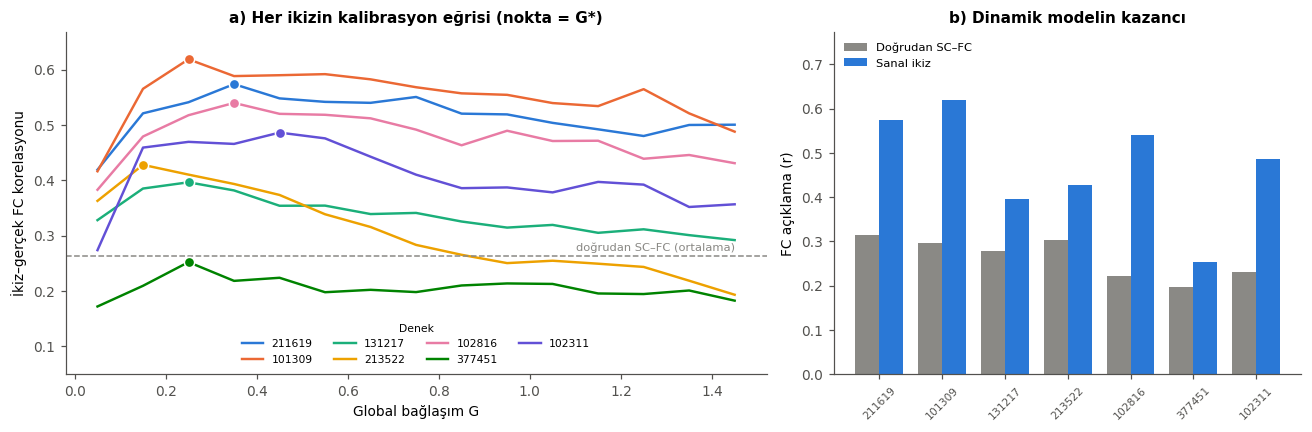

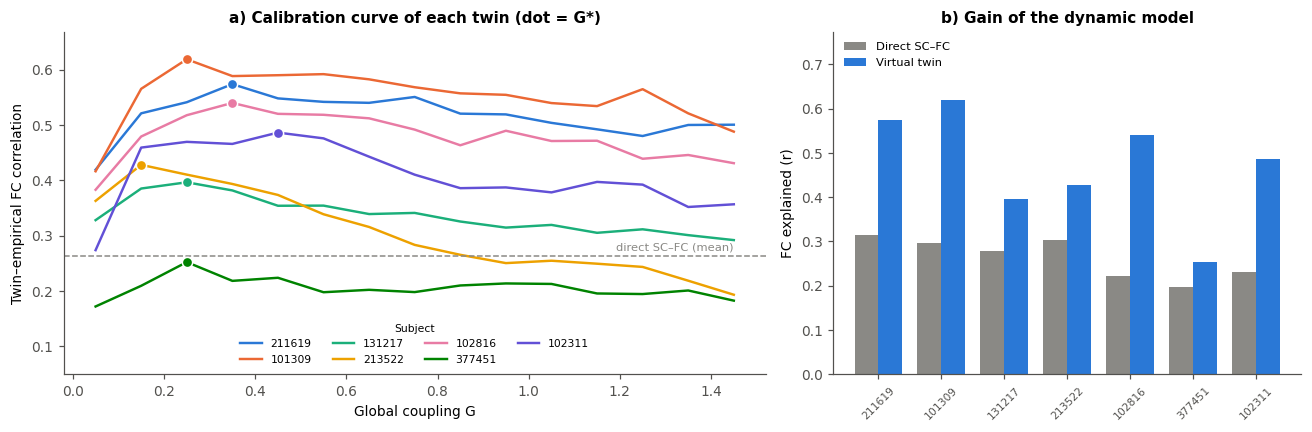

Kaydedildi -> sekiller/tr/sekil08_kalibrasyon.jpg  ve  sekiller/en/sekil08_kalibrasyon.jpg
İkiz vs doğrudan SC-FC: Wilcoxon W=0.0, p=0.0156 (n=7, tek değer en küçük p=0,0156)


In [17]:
# ŞEKİL 8: Kalibrasyon eğrileri ve kazanç
def ciz(dil):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.5, 1]})
    for s in range(NS):
        ax[0].plot(G_IZGARA, UYUM_EGRI[s], color=KAT[s], lw=1.6, label=DENEKLER[s])
        ax[0].scatter(G_EN_IYI[s], UYUM_EN_IYI[s], color=KAT[s], s=45, edgecolor="white", zorder=3)
    ax[0].axhline(np.mean(SCFC_HCP), color=GRI, ls="--", lw=1)
    ax[0].text(G_IZGARA[-1], np.mean(SCFC_HCP) + 0.01,
               T(dil, "doğrudan SC–FC (ortalama)", "direct SC–FC (mean)"), ha="right", fontsize=7.5, color=GRI)
    ax[0].set_xlabel(T(dil, "Global bağlaşım G", "Global coupling G"))
    ax[0].set_ylabel(T(dil, "İkiz–gerçek FC korelasyonu", "Twin–empirical FC correlation"))
    ax[0].set_title(T(dil, "a) Her ikizin kalibrasyon eğrisi (nokta = G*)",
                           "a) Calibration curve of each twin (dot = G*)"))
    ax[0].set_ylim(0.05, max(UYUM_EN_IYI) * 1.08)
    ax[0].legend(fontsize=7, ncol=4, loc="lower center", title=T(dil, "Denek", "Subject"), title_fontsize=7)
    x = np.arange(NS); wd = 0.38
    ax[1].bar(x - wd / 2, SCFC_HCP, wd, color=GRI, label=T(dil, "Doğrudan SC–FC", "Direct SC–FC"))
    ax[1].bar(x + wd / 2, UYUM_EN_IYI, wd, color=MAVI, label=T(dil, "Sanal ikiz", "Virtual twin"))
    ax[1].set_xticks(x); ax[1].set_xticklabels(DENEKLER, rotation=45, fontsize=7)
    ax[1].set_ylabel(T(dil, "FC açıklama (r)", "FC explained (r)"))
    ax[1].set_title(T(dil, "b) Dinamik modelin kazancı", "b) Gain of the dynamic model"))
    ax[1].legend(fontsize=7.5, loc="upper left"); ax[1].set_ylim(0, max(UYUM_EN_IYI) * 1.25)
    fig.tight_layout()
    return fig
iki_dilli(ciz, "sekil08_kalibrasyon")
st = wilcoxon(UYUM_EN_IYI, SCFC_HCP)
print(f"İkiz vs doğrudan SC-FC: Wilcoxon W={st.statistic:.1f}, p={st.pvalue:.4f} (n={NS}, tek değer en küçük p=0,0156)")

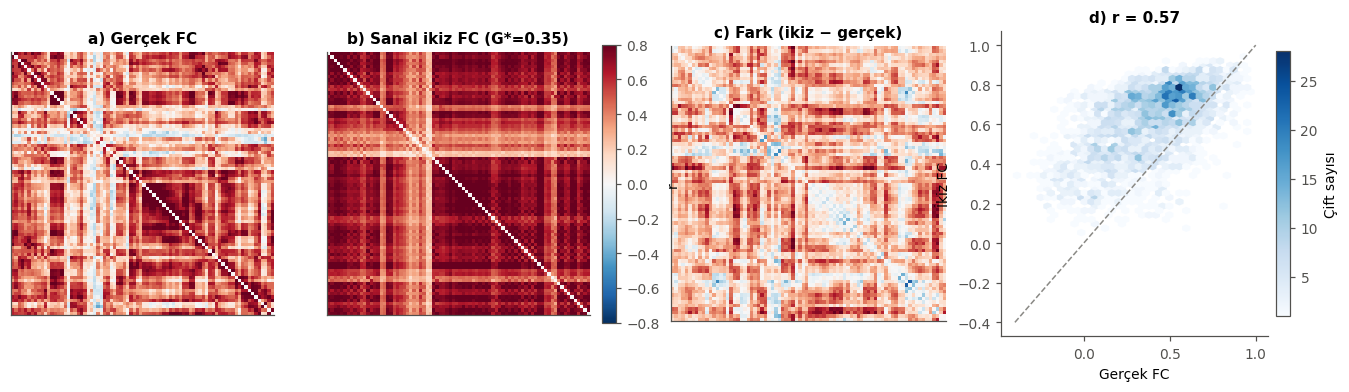

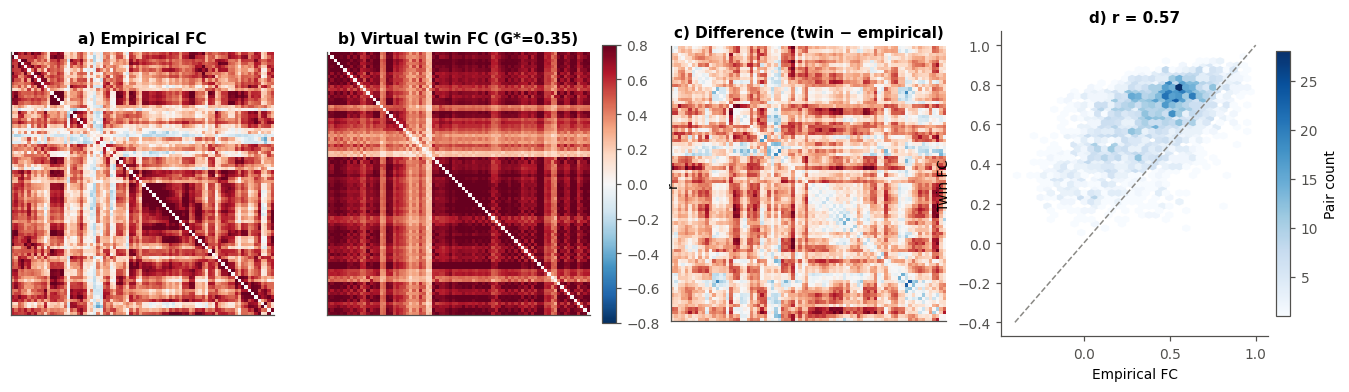

Kaydedildi -> sekiller/tr/sekil09_ikiz_vs_gercek.jpg  ve  sekiller/en/sekil09_ikiz_vs_gercek.jpg


In [18]:
# ŞEKİL 9: Örnek denek için gerçek ve ikiz FC yan yana
FC_IKIZ_ORNEK = SIM_FC_IKIZ[ORNEK, G_EN_IYI_IDX[ORNEK]]
def ciz(dil):
    fig, ax = plt.subplots(1, 4, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1, 1, 1, 1.05]})
    for a, M, ttl in [(ax[0], FC_EMP[ORNEK], T(dil, "a) Gerçek FC", "a) Empirical FC")),
                      (ax[1], FC_IKIZ_ORNEK, T(dil, f"b) Sanal ikiz FC (G*={G_EN_IYI[ORNEK]})",
                                               f"b) Virtual twin FC (G*={G_EN_IYI[ORNEK]})"))]:
        im = a.imshow(M - np.eye(N) * M, cmap=DIV, vmin=-0.8, vmax=0.8); a.set_title(ttl)
        a.set_xticks([]); a.set_yticks([])
    fig.colorbar(im, ax=ax[:2], fraction=0.023, pad=0.02, label="r")
    fark = FC_IKIZ_ORNEK - FC_EMP[ORNEK]
    im2 = ax[2].imshow(fark, cmap=DIV, vmin=-0.8, vmax=0.8)
    ax[2].set_title(T(dil, "c) Fark (ikiz − gerçek)", "c) Difference (twin − empirical)"))
    ax[2].set_xticks([]); ax[2].set_yticks([])
    hb = ax[3].hexbin(ust(FC_EMP[ORNEK]), ust(FC_IKIZ_ORNEK), gridsize=35, cmap=SEQ, mincnt=1)
    ax[3].plot([-0.4, 1], [-0.4, 1], color=GRI, ls="--", lw=1)
    ax[3].set_xlabel(T(dil, "Gerçek FC", "Empirical FC")); ax[3].set_ylabel(T(dil, "İkiz FC", "Twin FC"))
    ax[3].set_title(f"d) r = {UYUM_EN_IYI[ORNEK]:.2f}")
    fig.colorbar(hb, ax=ax[3], fraction=0.046, pad=0.03, label=T(dil, "Çift sayısı", "Pair count"))
    return fig
iki_dilli(ciz, "sekil09_ikiz_vs_gercek")

### 5.1 Dinamiğin zamansal yapısı: FCD karşılaştırması

Statik FC, beynin ~14 dakikalık "ortalama" bağlantı resmini veriyor. Oysa beyin bağlantıları zaman içinde değişiyor. Bu yüzden ikizin **zamanla değişen bağlantıyı** da yakalayıp yakalamadığına bakıyoruz. Bunun için **fonksiyonel bağlantı dinamiği (FCD)** ölçüsünü kullanıyoruz (Hansen ve ark., 2015):
1. Sinyal 60 TR'lik (≈43 s) kayan pencerelere bölünüyor.
2. Her pencerede bir FC hesaplanıyor.
3. Pencerelerin FC'leri birbiriyle karşılaştırılıyor.

Gerçek ve ikiz FCD dağılımları arasındaki benzerliği **Kolmogorov–Smirnov (KS) mesafesiyle** ölçüyoruz. Düşük KS, iyi uyum demek. Bu ölçü kalibrasyonda **kullanılmadı**, dolayısıyla bağımsız bir doğrulama sayılır.

FCD KS mesafeleri: [0.195 0.4   0.467 0.568 0.572 0.547 0.466] | ortalama: 0.459


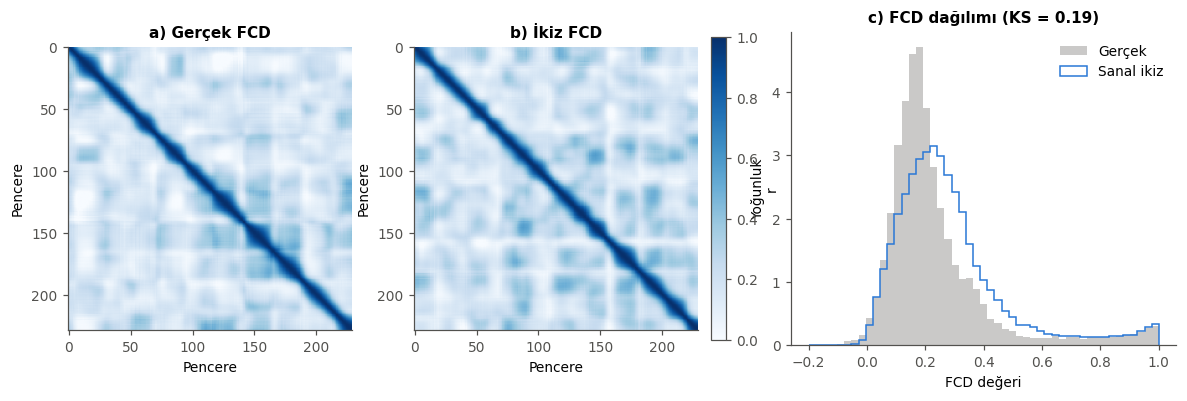

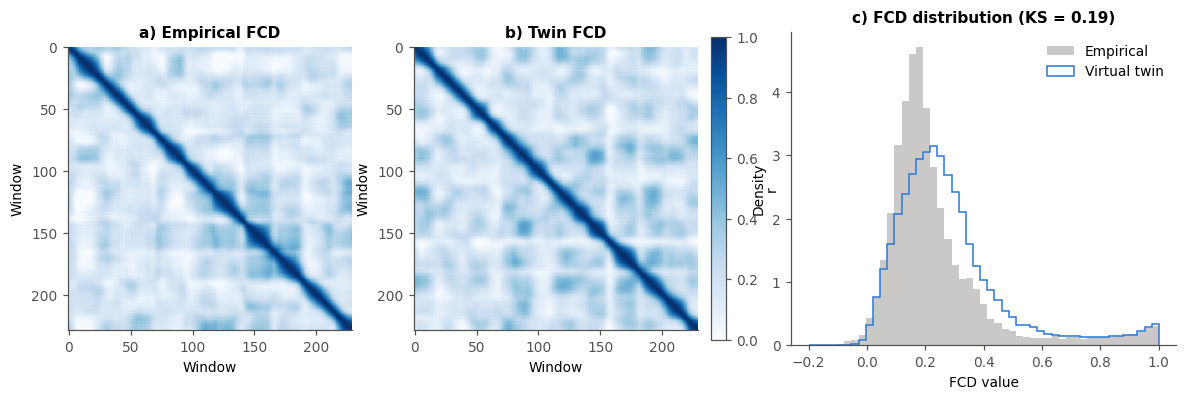

Kaydedildi -> sekiller/tr/sekil10_fcd.jpg  ve  sekiller/en/sekil10_fcd.jpg


In [19]:
def fcd(x, pencere=60, adim=5):
    # Kayan pencereli FC'lerin birbirleriyle korelasyonu (FCD matrisi).
    bas = range(0, x.shape[1] - pencere + 1, adim)
    v = np.array([ust(np.corrcoef(x[:, b:b + pencere])) for b in bas])
    return np.corrcoef(v)

def fcd_dagilim(M):
    return M[np.triu_indices(M.shape[0], 1)]

FCD_KS, FCD_EMP_DAG, FCD_SIM_DAG = [], [], []
for s in range(NS):
    e = fcd_dagilim(fcd(BOLD_F[s]))
    _, X = sim_fc(SC[s], G_EN_IYI[s], OMEGA[s], n_tohum=3, tohum=ANA_TOHUM + 7000 + s)
    sdag = np.concatenate([fcd_dagilim(fcd(suz(X[k]))) for k in range(X.shape[0])])
    FCD_EMP_DAG.append(e); FCD_SIM_DAG.append(sdag)
    FCD_KS.append(ks_2samp(e, sdag).statistic)
print("FCD KS mesafeleri:", np.round(FCD_KS, 3), "| ortalama:", round(np.mean(FCD_KS), 3))

def ciz(dil):
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.7), gridspec_kw={"width_ratios": [1, 1, 1.3]})
    M1 = fcd(BOLD_F[ORNEK])
    _, X = sim_fc(SC[ORNEK], G_EN_IYI[ORNEK], OMEGA[ORNEK], n_tohum=1, tohum=ANA_TOHUM + 7000)
    M2 = fcd(suz(X[0]))
    for a, M, ttl in [(ax[0], M1, T(dil, "a) Gerçek FCD", "a) Empirical FCD")),
                      (ax[1], M2, T(dil, "b) İkiz FCD", "b) Twin FCD"))]:
        im = a.imshow(M, cmap=SEQ, vmin=0, vmax=1)
        a.set_xlabel(T(dil, "Pencere", "Window")); a.set_ylabel(T(dil, "Pencere", "Window")); a.set_title(ttl)
    fig.colorbar(im, ax=ax[:2], fraction=0.023, pad=0.02, label="r")
    b = np.linspace(-0.2, 1, 50)
    ax[2].hist(FCD_EMP_DAG[ORNEK], bins=b, density=True, histtype="stepfilled", color=GRI, alpha=0.45,
               label=T(dil, "Gerçek", "Empirical"))
    ax[2].hist(FCD_SIM_DAG[ORNEK], bins=b, density=True, histtype="step", color=MAVI, lw=2,
               label=T(dil, "Sanal ikiz", "Virtual twin"))
    ax[2].set_xlabel(T(dil, "FCD değeri", "FCD value")); ax[2].set_ylabel(T(dil, "Yoğunluk", "Density"))
    ax[2].set_title(T(dil, f"c) FCD dağılımı (KS = {FCD_KS[ORNEK]:.2f})",
                           f"c) FCD distribution (KS = {FCD_KS[ORNEK]:.2f})"))
    ax[2].legend()
    return fig
iki_dilli(ciz, "sekil10_fcd")

## 6. Çapraz doğrulama: ikiz görmediği veriyi öngörebiliyor mu?

Bir "ikizin" en önemli özelliklerinden biri **öngörü** yapabilmesi; yani yalnızca gördüğü veriyi tekrar etmekten fazlasını yapması. Bunu test etmek için:
1. Her deneğin 1200 noktalık kaydını iki yarıya bölüyoruz: **1. yarı** (eğitim) ve **2. yarı** (test).
2. İkizi yalnızca 1. yarıyla kuruyoruz. Frekanslar ($\omega$) ve $G$ değeri yalnızca 1. yarıdan belirleniyor.
3. İkizin simüle FC'sini, hiç görmediği **2. yarının** FC'siyle karşılaştırıyoruz.

Elde edilen değeri bir **tavan değerle** kıyaslıyoruz. Tavan, aynı kişinin 1. yarı FC'si ile 2. yarı FC'si arasındaki korelasyon. Bu, verinin kendi gürültüsü nedeniyle ulaşılabilecek üst sınırı gösteriyor.

In [20]:
YARI = T_NOKTA // 2
CV = []
t0 = time.time()
for s in range(NS):
    b1, b2 = BOLD[s][:, :YARI], BOLD[s][:, YARI:]
    f1, f2 = suz(b1), suz(b2)
    fc1, fc2 = fc_hesapla(f1), fc_hesapla(f2)
    om1 = 2 * np.pi * tepe_frekans(f1)
    egri, fcs = [], []
    for g_i, G in enumerate(G_IZGARA):
        fs, _ = sim_fc(SC[s], G, om1, tohum=ANA_TOHUM + 3000 + 100 * s + g_i)
        fcs.append(fs); egri.append(uyum(fs, fc1))
    k = int(np.argmax(egri))
    CV.append({"Denek": DENEKLER[s], "G* (1. yarı)": G_IZGARA[k],
               "Eğitim r (1. yarı)": egri[k], "Test r (2. yarı)": uyum(fcs[k], fc2),
               "Tavan r (1. yarı ↔ 2. yarı)": uyum(fc1, fc2),
               "Doğrudan SC–FC r (2. yarı)": uyum(SC[s], fc2)})
CV = pd.DataFrame(CV)
CV["Tavanın yüzdesi (%)"] = 100 * CV["Test r (2. yarı)"] / CV["Tavan r (1. yarı ↔ 2. yarı)"]
CV.round(3).to_csv("ciktilar/tablo3_capraz_dogrulama.csv", index=False)
print(f"Süre: {time.time()-t0:.0f} s")
CV.round(3)

Süre: 194 s


,Denek,G* (1. yarı),Eğitim r (1. yarı),Test r (2. yarı),Tavan r (1. yarı ↔ 2. yarı),Doğrudan SC–FC r (2. yarı),Tavanın yüzdesi (%)
0,211619,0.15,0.320,0.553,0.540,0.280,102.478
1,101309,0.25,0.535,0.611,0.663,0.268,92.110
2,131217,0.15,0.268,0.414,0.623,0.281,66.396
3,213522,0.25,0.378,0.348,0.543,0.269,64.097
4,102816,0.45,0.520,0.544,0.913,0.207,59.542
5,377451,0.15,0.316,0.237,0.753,0.164,31.448
6,102311,0.35,0.421,0.477,0.743,0.193,64.213


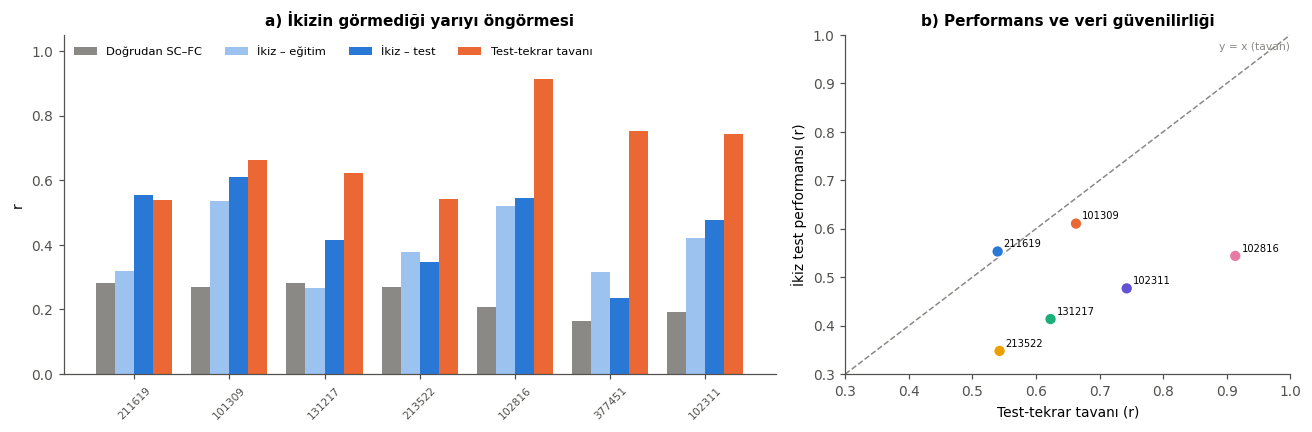

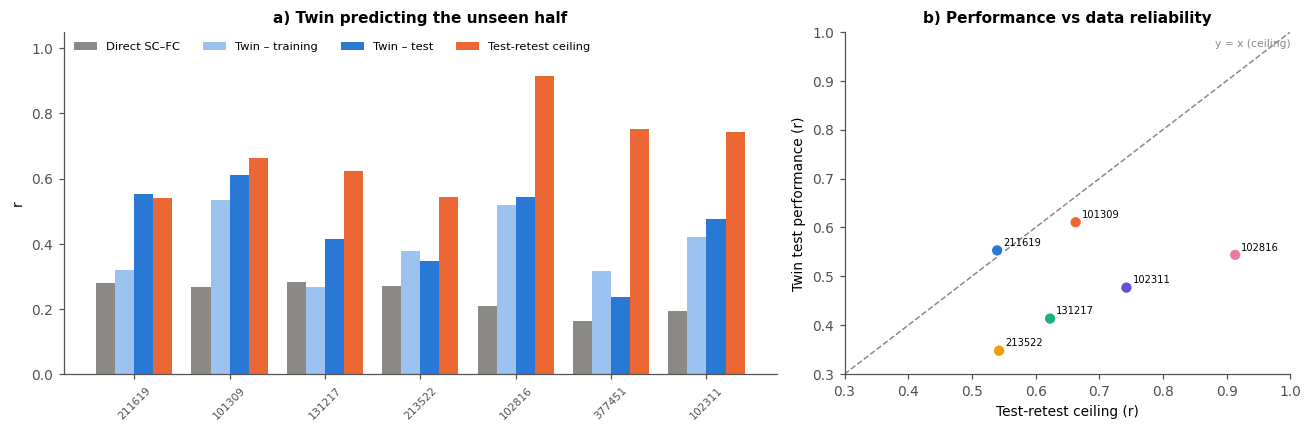

Kaydedildi -> sekiller/tr/sekil11_capraz_dogrulama.jpg  ve  sekiller/en/sekil11_capraz_dogrulama.jpg
Ortalama test r = 0.455; tavanın %69'i


In [21]:
# ŞEKİL 11: Çapraz doğrulama
def ciz(dil):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.6, 1]})
    x = np.arange(NS); wd = 0.2
    seriler = [("Doğrudan SC–FC r (2. yarı)", GRI, T(dil, "Doğrudan SC–FC", "Direct SC–FC")),
               ("Eğitim r (1. yarı)", "#9cc3ef", T(dil, "İkiz – eğitim", "Twin – training")),
               ("Test r (2. yarı)", MAVI, T(dil, "İkiz – test", "Twin – test")),
               ("Tavan r (1. yarı ↔ 2. yarı)", TURUNCU, T(dil, "Test-tekrar tavanı", "Test-retest ceiling"))]
    for k, (c, renk, lab) in enumerate(seriler):
        ax[0].bar(x + (k - 1.5) * wd, CV[c], wd, color=renk, label=lab)
    ax[0].set_xticks(x); ax[0].set_xticklabels(DENEKLER, rotation=45, fontsize=7)
    ax[0].set_ylabel("r"); ax[0].legend(fontsize=7.5, ncol=4, loc="upper left")
    ax[0].set_ylim(0, 1.05)
    ax[0].set_title(T(dil, "a) İkizin görmediği yarıyı öngörmesi", "a) Twin predicting the unseen half"))
    ax[1].scatter(CV["Tavan r (1. yarı ↔ 2. yarı)"], CV["Test r (2. yarı)"], c=KAT[:NS], s=60,
                  edgecolor="white", zorder=3)
    for _, r in CV.iterrows():
        ax[1].annotate(r["Denek"], (r["Tavan r (1. yarı ↔ 2. yarı)"], r["Test r (2. yarı)"]),
                       fontsize=6.5, xytext=(4, 3), textcoords="offset points")
    lo, hi = 0.3, 1.0
    ax[1].plot([lo, hi], [lo, hi], color=GRI, ls="--", lw=1)
    ax[1].text(hi, hi - 0.03, T(dil, "y = x (tavan)", "y = x (ceiling)"), ha="right", fontsize=7, color=GRI)
    ax[1].set_xlim(lo, hi); ax[1].set_ylim(lo, hi)
    ax[1].set_xlabel(T(dil, "Test-tekrar tavanı (r)", "Test-retest ceiling (r)"))
    ax[1].set_ylabel(T(dil, "İkiz test performansı (r)", "Twin test performance (r)"))
    ax[1].set_title(T(dil, "b) Performans ve veri güvenilirliği", "b) Performance vs data reliability"))
    fig.tight_layout()
    return fig
iki_dilli(ciz, "sekil11_capraz_dogrulama")
print(f"Ortalama test r = {CV['Test r (2. yarı)'].mean():.3f}; tavanın %{CV['Tavanın yüzdesi (%)'].mean():.0f}'i")

## 7. Kişiye özgülük testi: ikiz gerçekten o kişiye mi ait?

Literatürde dijital ikiz çalışmalarına yöneltilen temel eleştirilerden biri **kişiselleştirmenin gerçekten test edilmemesi**. Bu bölümde bunu doğrudan test ediyoruz.

**Deney tasarımı:** Her gerçek FC (denek $i$), sırasıyla şu ikizlerle karşılaştırılıyor:
- **Kendi ikizi** (SC$_i$, ω$_i$),
- **Diğer 6 kişinin ikizleri** (SC$_j$, ω$_j$, $j \neq i$),
- **Grup ortalaması ikizi:** 7 kişinin ortalama SC'si ve ortalama ω'su ile kurulan "jenerik" ikiz,
- **Ayrıştırma ikizleri:** "kendi SC + grup ω" ve "grup SC + kendi ω". Bu iki ikiz, kişiselleştirmenin hangi bileşeninin (yapı mı, ritim mi) işe yaradığını ayırmamızı sağlıyor.
- **Karıştırılmış ağ ikizi (sıfır modeli):** kişinin SC ağırlıklarının bağlantılar arasında rastgele karıştırılmış hali. Ağırlık dağılımı ve simetri korunuyor, ama "kim kime bağlı" bilgisi yok ediliyor.

> **Neden derece-korumalı yeniden bağlama (Maslov–Sneppen) kullanmadık?** Tablo 1'de görüldüğü gibi bu veri setindeki SC matrisleri **%100 yoğun**. Olasılıksal traktografi her bölge çifti için sıfırdan büyük bir değer üretiyor. Tam bağlı bir ağda kenar değiş-tokuşu yapılamaz; bu yüzden derece-korumalı yeniden bağlama hiçbir şeyi değiştirmez. Bu, olasılıksal traktografi verisiyle çalışan araştırmacıların dikkat etmesi gereken pratik bir nokta.

**Adillik:** Her karşılaştırmada $G$ değeri, o çift için ayrı ayrı en iyi değere ayarlanıyor. Böylece hiçbir ikiz parametre avantajıyla öne geçemiyor.

**Ölçüler:**
- **Kimliklendirme doğruluğu:** Gerçek FC'ye en iyi uyan ikiz, kişinin kendi ikizi mi?
- **Kişiselleştirme kazancı:** (kendi ikizi uyumu) − (diğer ikizlerin ortalama uyumu).
- **Permütasyon testi:** Etiketler 10.000 kez karıştırılarak kazancın şansla elde edilip edilemeyeceği sınanıyor.

In [22]:
# 7.1 Çapraz uyum matrisi: satır = gerçek FC (i), sütun = ikiz (j); her hücrede en iyi G
CAPRAZ = np.array([[max(uyum(SIM_FC_IKIZ[j, g], FC_EMP[i]) for g in range(len(G_IZGARA)))
                    for j in range(NS)] for i in range(NS)])
kendi = np.diag(CAPRAZ)
diger = np.array([CAPRAZ[i, np.arange(NS) != i].mean() for i in range(NS)])
dogru_kimlik = np.mean(CAPRAZ.argmax(1) == np.arange(NS))
kazanc = (kendi - diger).mean()

# Permütasyon testi: ikiz etiketlerini karıştır, köşegen - köşegen dışı farkını yeniden hesapla
rng = np.random.default_rng(ANA_TOHUM)
perm = []
for _ in range(10000):
    p = rng.permutation(NS)
    M = CAPRAZ[:, p]
    perm.append((np.diag(M) - (M.sum(1) - np.diag(M)) / (NS - 1)).mean())
perm = np.array(perm)
p_perm = (np.sum(perm >= kazanc) + 1) / (len(perm) + 1)

print(f"Kimliklendirme doğruluğu: {dogru_kimlik*100:.0f}% (şans düzeyi {100/NS:.0f}%)")
print(f"Kendi ikizi ortalama r = {kendi.mean():.3f} | diğer ikizler ortalama r = {diger.mean():.3f}")
print(f"Kişiselleştirme kazancı Δr = {kazanc:.4f} | permütasyon p = {p_perm:.4f}")

Kimliklendirme doğruluğu: 14% (şans düzeyi 14%)
Kendi ikizi ortalama r = 0.471 | diğer ikizler ortalama r = 0.478
Kişiselleştirme kazancı Δr = -0.0074 | permütasyon p = 0.7844


In [23]:
# 7.2 Grup ortalaması ikizi, ayrıştırma ikizleri ve karıştırılmış ağ ikizi
SC_GRUP = np.mean(SC, axis=0)
OMEGA_GRUP = np.mean(OMEGA, axis=0)
print(f"SC yoğunluğu: %{100*np.mean(ust(SC[0]) > 0):.0f} -> derece-korumalı yeniden bağlama mümkün değil")

def agirlik_karistir(C, tohum=0):
    # Üst üçgendeki ağırlıkları rastgele karıştırır, simetrik matris döndürür.
    # Ağırlık dağılımı aynen korunur; bağlantı topolojisi (kim kime) yok edilir.
    rng = np.random.default_rng(tohum)
    A = np.zeros_like(C); w = C[iu].copy(); rng.shuffle(w)
    A[iu] = w; return A + A.T

def en_iyi_uyum(fc_dizisi, fc_hedef):
    # G ızgarası üzerinde en iyi uyum (her ikiz kendi en iyi G'sinde değerlendirilir)
    return max(uyum(f, fc_hedef) for f in fc_dizisi)

t0 = time.time()
SIM_FC_GRUP = np.array([sim_fc(SC_GRUP, G, OMEGA_GRUP, n_tohum=N_TOHUM, tohum=ANA_TOHUM + 5000 + g)[0]
                        for g, G in enumerate(G_IZGARA)])
SC_KARIS = [agirlik_karistir(SC[s], tohum=ANA_TOHUM + s) for s in range(NS)]
grup_uyum, karis_uyum, kendiSC_grupW, grupSC_kendiW = [], [], [], []
for s in range(NS):
    fk = [sim_fc(SC_KARIS[s], G, OMEGA[s], n_tohum=N_TOHUM, tohum=ANA_TOHUM + 6000 + 100 * s + g)[0]
          for g, G in enumerate(G_IZGARA)]
    f1 = [sim_fc(SC[s], G, OMEGA_GRUP, n_tohum=N_TOHUM, tohum=ANA_TOHUM + 8000 + 100 * s + g)[0]
          for g, G in enumerate(G_IZGARA)]
    f2 = [sim_fc(SC_GRUP, G, OMEGA[s], n_tohum=N_TOHUM, tohum=ANA_TOHUM + 8500 + 100 * s + g)[0]
          for g, G in enumerate(G_IZGARA)]
    grup_uyum.append(en_iyi_uyum(SIM_FC_GRUP, FC_EMP[s])); karis_uyum.append(en_iyi_uyum(fk, FC_EMP[s]))
    kendiSC_grupW.append(en_iyi_uyum(f1, FC_EMP[s])); grupSC_kendiW.append(en_iyi_uyum(f2, FC_EMP[s]))
    print(f"{DENEKLER[s]} tamam ({time.time()-t0:.0f} s)")
grup_uyum, karis_uyum = np.array(grup_uyum), np.array(karis_uyum)
kendiSC_grupW, grupSC_kendiW = np.array(kendiSC_grupW), np.array(grupSC_kendiW)
print("Karıştırmada ağırlık dağılımı korundu mu?",
      all(np.allclose(np.sort(ust(SC_KARIS[s])), np.sort(ust(SC[s]))) for s in range(NS)))

KARS = pd.DataFrame({"Denek": DENEKLER, "Kendi ikizi": kendi, "Diğer ikizler (ort.)": diger,
                     "Grup ortalaması ikizi": grup_uyum,
                     "Kendi SC + grup ω": kendiSC_grupW, "Grup SC + kendi ω": grupSC_kendiW,
                     "Karıştırılmış ağ ikizi": karis_uyum, "Doğrudan SC–FC": SCFC_HCP})
KARS.round(3).to_csv("ciktilar/tablo4_kisiye_ozgululuk.csv", index=False)
for c in ["Diğer ikizler (ort.)", "Grup ortalaması ikizi", "Kendi SC + grup ω", "Grup SC + kendi ω",
          "Karıştırılmış ağ ikizi"]:
    st = wilcoxon(KARS["Kendi ikizi"], KARS[c])
    print(f"Kendi ikizi vs {c:24s}: ort. fark = {(KARS['Kendi ikizi']-KARS[c]).mean():+.4f}, "
          f"Wilcoxon p = {st.pvalue:.4f}")
KARS.round(3)

SC yoğunluğu: %100 -> derece-korumalı yeniden bağlama mümkün değil
211619 tamam (134 s)
101309 tamam (236 s)
131217 tamam (338 s)
213522 tamam (439 s)
102816 tamam (558 s)
377451 tamam (661 s)
102311 tamam (764 s)
Karıştırmada ağırlık dağılımı korundu mu? True
Kendi ikizi vs Diğer ikizler (ort.)    : ort. fark = -0.0074, Wilcoxon p = 0.9375
Kendi ikizi vs Grup ortalaması ikizi   : ort. fark = -0.0240, Wilcoxon p = 0.2969
Kendi ikizi vs Kendi SC + grup ω       : ort. fark = -0.0027, Wilcoxon p = 1.0000
Kendi ikizi vs Grup SC + kendi ω       : ort. fark = -0.0167, Wilcoxon p = 0.2188
Kendi ikizi vs Karıştırılmış ağ ikizi  : ort. fark = +0.4061, Wilcoxon p = 0.0156


,Denek,Kendi ikizi,Diğer ikizler (ort.),Grup ortalaması ikizi,Kendi SC + grup ω,Grup SC + kendi ω,Karıştırılmış ağ ikizi,Doğrudan SC–FC
0,211619,0.574,0.538,0.551,0.568,0.540,0.017,0.315
1,101309,0.619,0.589,0.608,0.593,0.628,0.065,0.295
2,131217,0.396,0.386,0.424,0.402,0.401,0.060,0.279
3,213522,0.428,0.438,0.435,0.415,0.432,0.106,0.302
4,102816,0.540,0.634,0.639,0.582,0.638,0.128,0.221
5,377451,0.252,0.288,0.309,0.250,0.269,-0.029,0.197
6,102311,0.486,0.474,0.496,0.504,0.504,0.105,0.232


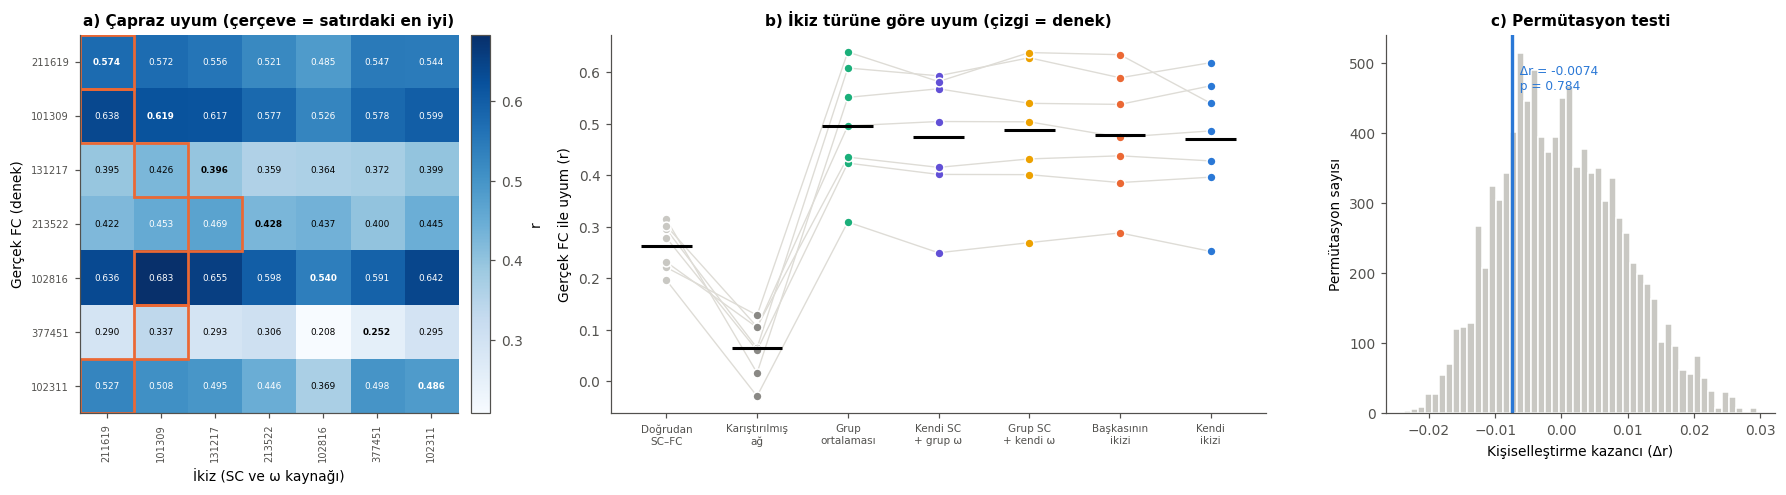

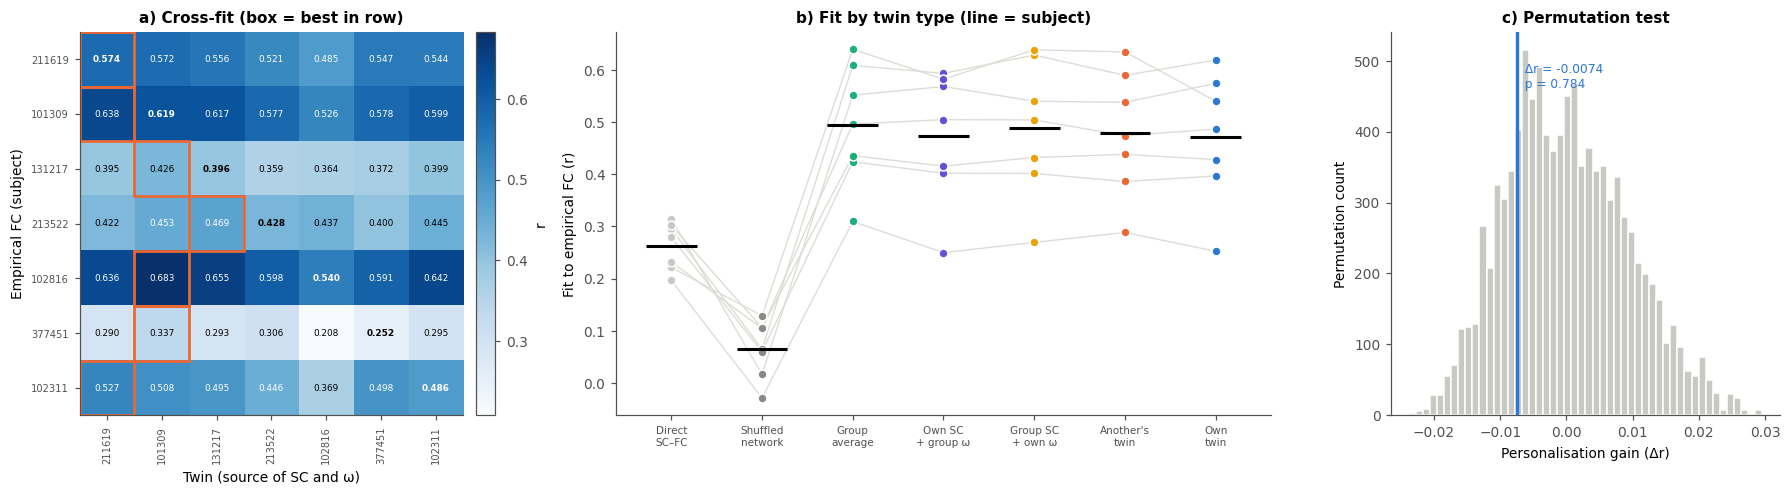

Kaydedildi -> sekiller/tr/sekil12_kisiye_ozgulluk.jpg  ve  sekiller/en/sekil12_kisiye_ozgulluk.jpg


In [24]:
# ŞEKİL 12: Kişiye özgülük
def ciz(dil):
    fig, ax = plt.subplots(1, 3, figsize=(16.5, 4.4), gridspec_kw={"width_ratios": [1.05, 1.6, 0.95]})
    vmin, vmax = CAPRAZ.min(), CAPRAZ.max()
    im = ax[0].imshow(CAPRAZ, cmap=SEQ, vmin=vmin, vmax=vmax)
    for i in range(NS):
        for j in range(NS):
            ax[0].text(j, i, f"{CAPRAZ[i, j]:.3f}", ha="center", va="center", fontsize=5.8,
                       color="white" if CAPRAZ[i, j] > (vmin + vmax) / 2 else "black",
                       fontweight="bold" if i == j else "normal")
        ax[0].add_patch(plt.Rectangle((CAPRAZ[i].argmax() - 0.5, i - 0.5), 1, 1, fill=False,
                                      ec=TURUNCU, lw=1.8))
    ax[0].set_xticks(range(NS)); ax[0].set_yticks(range(NS))
    ax[0].set_xticklabels(DENEKLER, rotation=90, fontsize=6.5); ax[0].set_yticklabels(DENEKLER, fontsize=6.5)
    ax[0].set_xlabel(T(dil, "İkiz (SC ve ω kaynağı)", "Twin (source of SC and ω)"))
    ax[0].set_ylabel(T(dil, "Gerçek FC (denek)", "Empirical FC (subject)"))
    ax[0].set_title(T(dil, "a) Çapraz uyum (çerçeve = satırdaki en iyi)", "a) Cross-fit (box = best in row)"))
    fig.colorbar(im, ax=ax[0], fraction=0.046, pad=0.03, label="r")
    kol = [("Doğrudan SC–FC", "#c9c8c3", T(dil, "Doğrudan\nSC–FC", "Direct\nSC–FC")),
           ("Karıştırılmış ağ ikizi", GRI, T(dil, "Karıştırılmış\nağ", "Shuffled\nnetwork")),
           ("Grup ortalaması ikizi", YESIL, T(dil, "Grup\nortalaması", "Group\naverage")),
           ("Kendi SC + grup ω", MOR, T(dil, "Kendi SC\n+ grup ω", "Own SC\n+ group ω")),
           ("Grup SC + kendi ω", SARI, T(dil, "Grup SC\n+ kendi ω", "Group SC\n+ own ω")),
           ("Diğer ikizler (ort.)", TURUNCU, T(dil, "Başkasının\nikizi", "Another's\ntwin")),
           ("Kendi ikizi", MAVI, T(dil, "Kendi\nikizi", "Own\ntwin"))]
    K = len(kol)
    for s in range(NS):
        ax[1].plot(range(K), [KARS.loc[s, c] for c, _, _ in kol], color="#dedcd6", lw=0.9, zorder=1)
    for k, (c, renk, _) in enumerate(kol):
        ax[1].scatter(np.full(NS, k), KARS[c], color=renk, s=34, edgecolor="white", zorder=3)
        ax[1].hlines(KARS[c].mean(), k - 0.28, k + 0.28, color="black", lw=2, zorder=4)
    ax[1].set_xticks(range(K)); ax[1].set_xticklabels([l for _, _, l in kol], fontsize=6.8)
    ax[1].set_ylabel(T(dil, "Gerçek FC ile uyum (r)", "Fit to empirical FC (r)"))
    ax[1].set_title(T(dil, "b) İkiz türüne göre uyum (çizgi = denek)", "b) Fit by twin type (line = subject)"))
    ax[2].hist(perm, bins=50, color="#c9c8c3", edgecolor="white")
    ax[2].axvline(kazanc, color=MAVI, lw=2.2)
    ax[2].text(kazanc, ax[2].get_ylim()[1] * 0.92, f"  Δr = {kazanc:.4f}\n  p = {p_perm:.3f}",
               color=MAVI, fontsize=8, va="top")
    ax[2].set_xlabel(T(dil, "Kişiselleştirme kazancı (Δr)", "Personalisation gain (Δr)"))
    ax[2].set_ylabel(T(dil, "Permütasyon sayısı", "Permutation count"))
    ax[2].set_title(T(dil, "c) Permütasyon testi", "c) Permutation test"))
    fig.tight_layout()
    return fig
iki_dilli(ciz, "sekil12_kisiye_ozgulluk")

**Yorum:** Bu bölümün sonucu iki katmanlı ve makalenin en önemli bulgusu:

1. **Bağlantıomun düzeni çok önemli.** Ağırlıklar karıştırıldığında, yani "kim kime bağlı" bilgisi yok edildiğinde, ikizin uyumu neredeyse sıfıra iniyor (r ≈ 0,05). Gerçek ağla kurulan tüm ikizler ise r ≈ 0,47–0,50 aralığında. Dolayısıyla model, işlevi gerçekten **yapıdan** üretiyor.
2. **Ama o yapının "kime ait olduğu" önemli değil.** Kişinin kendi ikizi; başkasının ikizinden, grup ortalaması ikizinden ve ayrıştırma ikizlerinden daha iyi uymuyor. Kimliklendirme doğruluğu şans düzeyinde, permütasyon testi anlamsız.

Bunun en olası nedeni Bölüm 3'te görüldü: insanların yapısal bağlantıomları birbirine %97 benziyor, bireysel farklar ise ölçüm gürültüsü düzeyinde. Bu bulgu, bireysel SC'nin bireysel FC'yi zayıf öngördüğünü gösteren ampirik çalışmalarla (Zimmermann ve ark., 2019) uyumlu. Pratik mesaj şu: **"Kişiye özel dijital ikiz" iddiası varsayılmamalı, bu bölümdeki gibi açıkça test edilmeli.** Kişiselleştirme ancak yapının belirgin biçimde farklılaştığı durumlarda (lezyon, tümör, rezeksiyon, epileptojenik ağ) ya da daha zengin kişisel veriyle (bölgesel heterojenlik, uzun kayıtlar, birden fazla oturum) beklenebilir.

## 8. Sanal müdahale: sanal lezyon deneyi

Dijital ikizin klinik değeri, **gerçek hastada yapılamayacak deneylerin** bilgisayarda yapılabilmesinden gelir. Örneğin bir tümör ameliyatında hangi bölgenin çıkarılmasının ağı ne kadar etkileyeceği önceden sorulabilir.

**Deney:** Her denek için 80 bölgenin her birini sırayla "çıkarıyoruz". Bunun için o bölgenin tüm yapısal bağlantılarını sıfırlıyoruz ve ikizi kalibre edilmiş $G^*$ değerinde yeniden çalıştırıyoruz.

**Ölçü (ağ bozulması):** Lezyonlu ikizin FC'si ile sağlam ikizin FC'si arasındaki farkı ölçüyoruz: $1 - r$. Hesaba yalnızca **kalan 79 bölge** dahil ediliyor. Sağlam ve lezyonlu ikizlerde **aynı gürültü tohumu** kullanılıyor (ortak rastgele sayılar yöntemi). Böylece gözlenen fark gürültüden değil, lezyondan kaynaklanıyor.

**Güvenilirlik kontrolü:** Tüm deney, birbirinden bağımsız **iki ayrı tohum setiyle** (A ve B) tekrarlanıyor. Her denek için A ve B'den elde edilen 80 bölgelik bozulma haritaları birbiriyle karşılaştırılıyor (Spearman ρ). Yüksek ρ, lezyon haritasının simülasyon gürültüsüne değil, ikizin yapısına bağlı olduğunu gösteriyor. Sonuç olarak A ve B'nin ortalaması kullanılıyor.

**Klinik soru:** Bozulma en çok hangi bölgelerde büyük? Bozulmanın büyüklüğü, bölgenin yapısal "merkezliği" (düğüm gücü) ile ne kadar ilişkili?

⏱️ 7 denek × 80 bölge × 2 tohum seti = 1120 simülasyon. Colab'da yaklaşık 6–12 dakika sürer.

In [25]:
def lezyon_haritasi(s, tohum, n_tohum=3):
    # Denek s'nin ikizinde 80 bölgeyi tek tek çıkarır; her lezyon için ağ bozulmasını döndürür.
    fc_saglam, _ = sim_fc(SC[s], G_EN_IYI[s], OMEGA[s], n_tohum=n_tohum, tohum=tohum)
    ii = np.triu_indices(N - 1, 1); boz = np.zeros(N)
    for k in range(N):
        C = SC[s].copy(); C[k, :] = 0; C[:, k] = 0          # bölge k'nin tüm bağlantılarını kes
        fc_lez, _ = sim_fc(C, G_EN_IYI[s], OMEGA[s], n_tohum=n_tohum, tohum=tohum)  # aynı tohum
        kalan = np.arange(N) != k
        a = fc_saglam[np.ix_(kalan, kalan)]; b = fc_lez[np.ix_(kalan, kalan)]
        boz[k] = 1 - pearsonr(a[ii], b[ii])[0]
    return boz

t0 = time.time()
BOZ_A = np.zeros((NS, N)); BOZ_B = np.zeros((NS, N)); GUVENILIRLIK = np.zeros(NS)
for s in range(NS):
    BOZ_A[s] = lezyon_haritasi(s, ANA_TOHUM + 9000 + s)
    BOZ_B[s] = lezyon_haritasi(s, ANA_TOHUM + 9500 + s)
    GUVENILIRLIK[s] = spearmanr(BOZ_A[s], BOZ_B[s])[0]
    print(f"{DENEKLER[s]}: tamam ({time.time()-t0:.0f} s) | A–B güvenilirliği ρ = {GUVENILIRLIK[s]:.3f}")

BOZULMA = (BOZ_A + BOZ_B) / 2
BOZ_ORT = BOZULMA.mean(0)
GUC_ORT = np.mean(GUC, axis=0)
rho, p_rho = spearmanr(GUC_ORT, BOZ_ORT)
print(f"\nLezyon haritası güvenilirliği (A–B) ortalama ρ = {GUVENILIRLIK.mean():.3f}")
print(f"Bozulma–düğüm gücü Spearman ρ = {rho:.3f}, p = {p_rho:.2e}")
# Denek bazında da aynı ilişki
rho_denek = [spearmanr(GUC[s], BOZULMA[s])[0] for s in range(NS)]
print("Denek bazında bozulma–güç ρ:", np.round(rho_denek, 2))
LEZ = pd.DataFrame({"Bölge": BOLGE, "Ortalama bozulma": BOZ_ORT, "SS": BOZULMA.std(0),
                    "Düğüm gücü (ort.)": GUC_ORT}).sort_values("Ortalama bozulma", ascending=False)
LEZ.round(4).to_csv("ciktilar/tablo5_sanal_lezyon.csv", index=False)
LEZ.head(10).round(4)

211619: tamam (236 s) | A–B güvenilirliği ρ = 0.884
101309: tamam (473 s) | A–B güvenilirliği ρ = 0.880
131217: tamam (711 s) | A–B güvenilirliği ρ = 0.842
213522: tamam (946 s) | A–B güvenilirliği ρ = 0.798
102816: tamam (1181 s) | A–B güvenilirliği ρ = 0.854
377451: tamam (1417 s) | A–B güvenilirliği ρ = 0.827
102311: tamam (1654 s) | A–B güvenilirliği ρ = 0.863

Lezyon haritası güvenilirliği (A–B) ortalama ρ = 0.850
Bozulma–düğüm gücü Spearman ρ = 0.788, p = 4.27e-18
Denek bazında bozulma–güç ρ: [0.69 0.82 0.73 0.9  0.44 0.76 0.66]


,Bölge,Ortalama bozulma,SS,Düğüm gücü (ort.)
74,Temporal_Mid_L,0.0054,0.0009,3.8619
71,Temporal_Sup_R,0.0043,0.0011,2.5204
75,Temporal_Mid_R,0.0040,0.0011,3.2547
5,Frontal_Mid_2_R,0.0039,0.0008,3.0049
48,Occipital_Mid_L,0.0036,0.0008,3.2861
2,Frontal_Sup_2_L,0.0035,0.0009,3.7694
70,Temporal_Sup_L,0.0034,0.0007,2.3581
4,Frontal_Mid_2_L,0.0033,0.0008,3.0644
3,Frontal_Sup_2_R,0.0033,0.0010,3.6824
32,Insula_L,0.0031,0.0006,2.0782


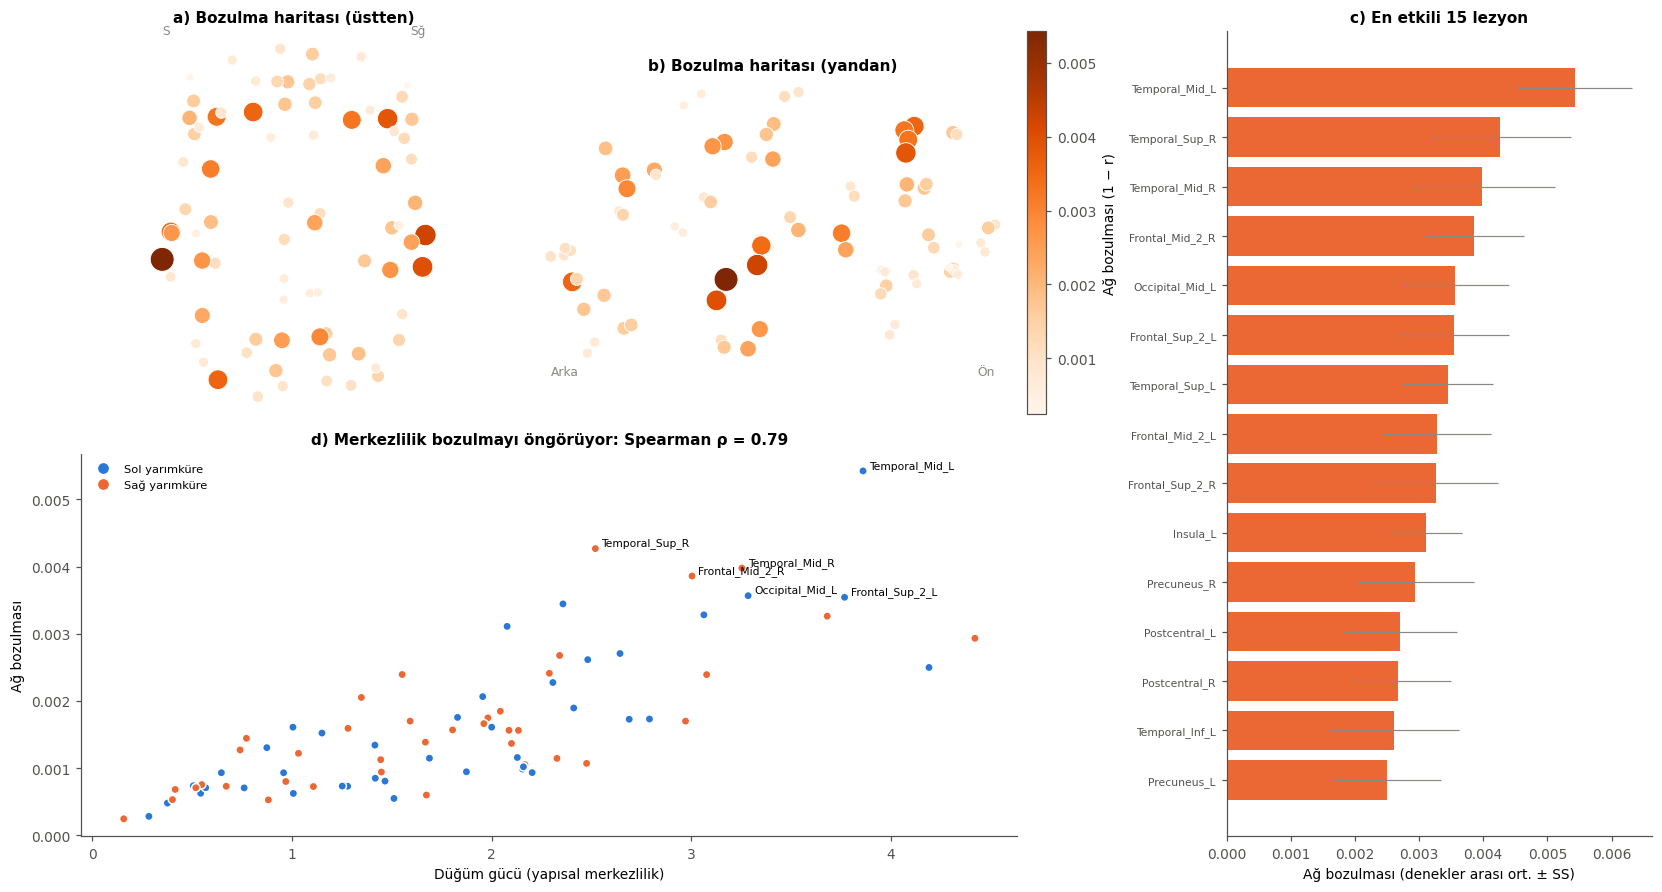

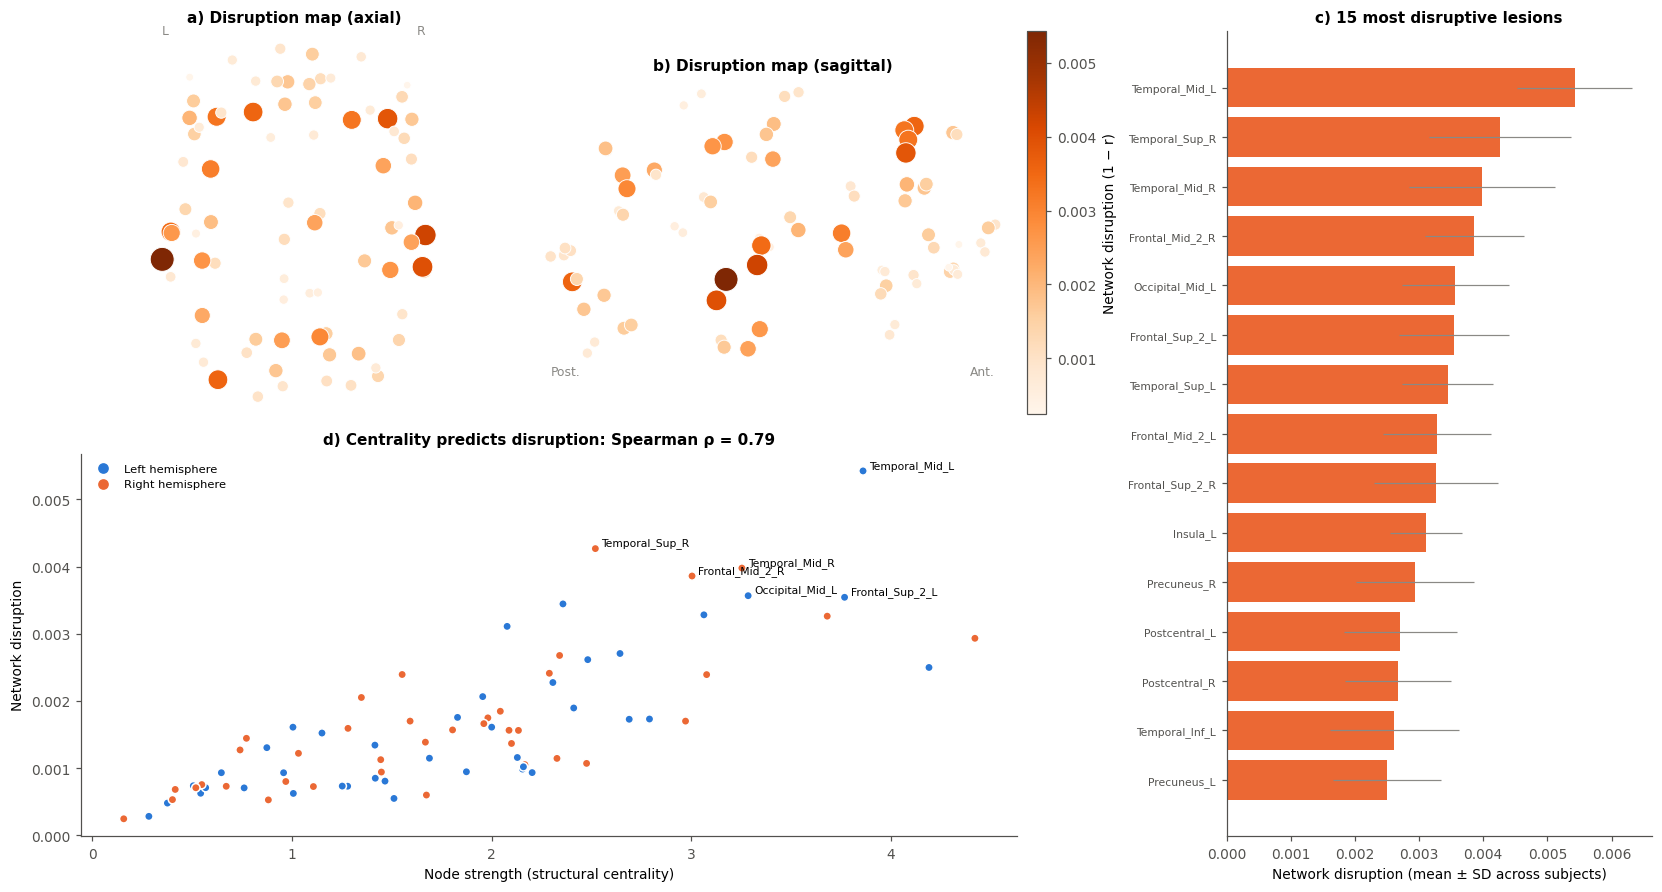

Kaydedildi -> sekiller/tr/sekil13_sanal_lezyon.jpg  ve  sekiller/en/sekil13_sanal_lezyon.jpg


In [26]:
# ŞEKİL 13: Sanal lezyon sonuçları
def ciz(dil):
    fig, axd = plt.subplot_mosaic([["a", "b", "c"], ["d", "d", "c"]], figsize=(15, 8),
                                  width_ratios=[1, 1.15, 1], layout="constrained")
    a0, a1, a2, a3 = axd["a"], axd["b"], axd["c"], axd["d"]
    boy = 25 + 220 * (BOZ_ORT - BOZ_ORT.min()) / (BOZ_ORT.max() - BOZ_ORT.min())
    sc = beyin_ciz(a0, BOZ_ORT, dil, "aksiyel", boyut=boy, cmap="Oranges",
                   baslik=T(dil, "a) Bozulma haritası (üstten)", "a) Disruption map (axial)"))
    beyin_ciz(a1, BOZ_ORT, dil, "sagittal", boyut=boy, cmap="Oranges",
              baslik=T(dil, "b) Bozulma haritası (yandan)", "b) Disruption map (sagittal)"))
    fig.colorbar(sc, ax=a1, fraction=0.05, pad=0.02, label=T(dil, "Ağ bozulması (1 − r)", "Network disruption (1 − r)"))
    top = LEZ.head(15).iloc[::-1]
    a2.barh(top["Bölge"], top["Ortalama bozulma"], xerr=top["SS"], color=TURUNCU,
            error_kw={"ecolor": GRI, "lw": 0.8})
    a2.set_xlabel(T(dil, "Ağ bozulması (denekler arası ort. ± SS)", "Network disruption (mean ± SD across subjects)"))
    a2.set_title(T(dil, "c) En etkili 15 lezyon", "c) 15 most disruptive lesions")); a2.tick_params(axis="y", labelsize=7)
    a3.scatter(GUC_ORT, BOZ_ORT, c=[MAVI if h == 0 else TURUNCU for h in HEMI], s=30, edgecolor="white")
    for k in np.argsort(BOZ_ORT)[::-1][:6]:
        a3.annotate(BOLGE[k], (GUC_ORT[k], BOZ_ORT[k]), fontsize=7, xytext=(4, 2), textcoords="offset points")
    a3.set_xlabel(T(dil, "Düğüm gücü (yapısal merkezlilik)", "Node strength (structural centrality)"))
    a3.set_ylabel(T(dil, "Ağ bozulması", "Network disruption"))
    a3.set_title(T(dil, f"d) Merkezlilik bozulmayı öngörüyor: Spearman ρ = {rho:.2f}",
                        f"d) Centrality predicts disruption: Spearman ρ = {rho:.2f}"))
    a3.legend(handles=[Line2D([], [], marker="o", ls="", color=MAVI, label=T(dil, "Sol yarımküre", "Left hemisphere")),
                       Line2D([], [], marker="o", ls="", color=TURUNCU, label=T(dil, "Sağ yarımküre", "Right hemisphere"))],
              fontsize=7.5, loc="upper left")
    return fig
iki_dilli(ciz, "sekil13_sanal_lezyon")

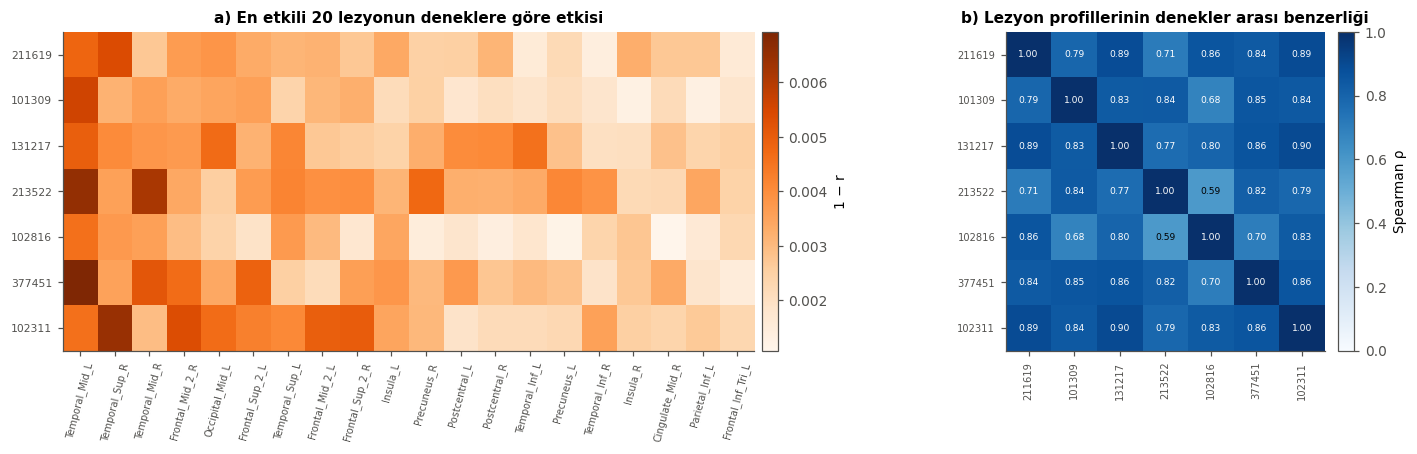

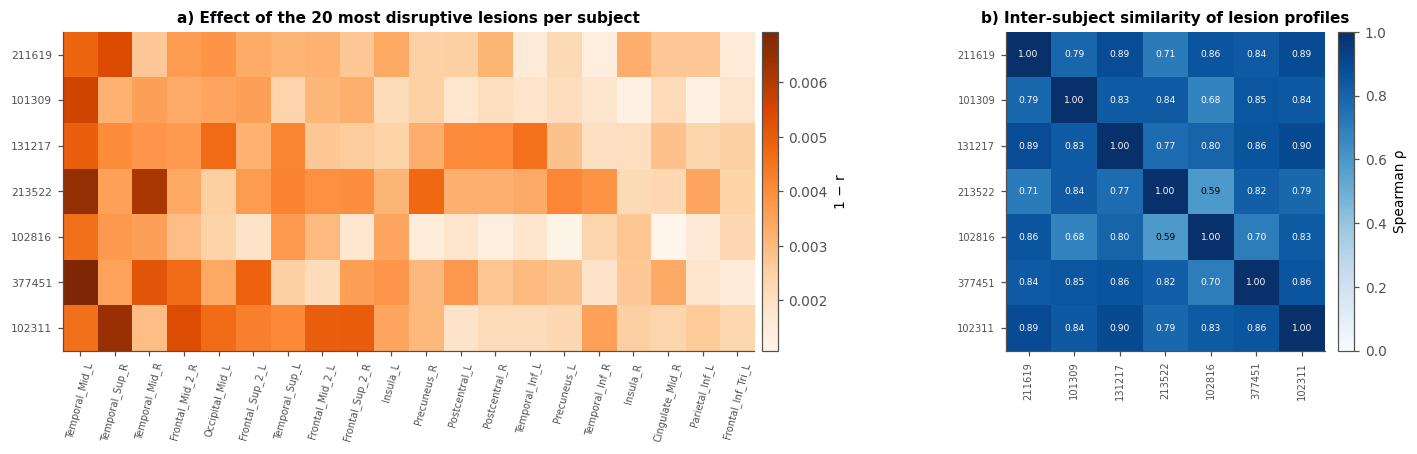

Kaydedildi -> sekiller/tr/sekil14_lezyon_bireysel.jpg  ve  sekiller/en/sekil14_lezyon_bireysel.jpg
Lezyon profillerinin denekler arası ortalama benzerliği ρ = 0.806


In [27]:
# ŞEKİL 14: Lezyon etkisinin kişiden kişiye değişimi (kişiselleştirmenin klinik anlamı)
def ciz(dil):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
    sira = np.argsort(BOZ_ORT)[::-1][:20]
    im = ax[0].imshow(BOZULMA[:, sira], aspect="auto", cmap="Oranges")
    ax[0].set_yticks(range(NS)); ax[0].set_yticklabels(DENEKLER, fontsize=7)
    ax[0].set_xticks(range(len(sira))); ax[0].set_xticklabels([BOLGE[k] for k in sira], rotation=75, fontsize=6.5)
    ax[0].set_title(T(dil, "a) En etkili 20 lezyonun deneklere göre etkisi", "a) Effect of the 20 most disruptive lesions per subject"))
    fig.colorbar(im, ax=ax[0], fraction=0.025, pad=0.01, label="1 − r")
    R = np.array([[spearmanr(BOZULMA[a], BOZULMA[b])[0] for b in range(NS)] for a in range(NS)])
    im2 = ax[1].imshow(R, cmap=SEQ, vmin=0, vmax=1)
    for p in range(NS):
        for q in range(NS):
            ax[1].text(q, p, f"{R[p, q]:.2f}", ha="center", va="center", fontsize=6,
                       color="white" if R[p, q] > 0.6 else "black")
    ax[1].set_xticks(range(NS)); ax[1].set_yticks(range(NS))
    ax[1].set_xticklabels(DENEKLER, rotation=90, fontsize=6.5); ax[1].set_yticklabels(DENEKLER, fontsize=6.5)
    ax[1].set_title(T(dil, "b) Lezyon profillerinin denekler arası benzerliği",
                           "b) Inter-subject similarity of lesion profiles"))
    fig.colorbar(im2, ax=ax[1], fraction=0.046, pad=0.03, label="Spearman ρ")
    fig.tight_layout()
    return fig
iki_dilli(ciz, "sekil14_lezyon_bireysel")
R_LEZ = np.array([[spearmanr(BOZULMA[a], BOZULMA[b])[0] for b in range(NS)] for a in range(NS)])
print(f"Lezyon profillerinin denekler arası ortalama benzerliği ρ = {R_LEZ[~np.eye(NS, dtype=bool)].mean():.3f}")

## 9. Literatür bileşeni: OpenAlex bibliyometrisi ve Türkiye

Makalenin derleme kısmını **gerçek yayın verisiyle** desteklemek için açık bibliyografik veri tabanı **OpenAlex**'i kullanıyoruz (Priem ve ark., 2022). Sorgularımız:

1. Başlık veya özetinde **"digital twin"** ifadesi geçen ve **beyin / nöro** terimlerinden birini içeren yayınların yıllara göre sayısı.
2. Aynı yayınların **ülkelere göre** dağılımı (yazar kurumlarının ülkesi) ve Türkiye'nin sırası.
3. Genel olarak **sağlıkta dijital ikiz** yayınlarında Türkiye'nin payı.
4. Türkiye adresli beyin/nöro dijital ikiz yayınlarının listesi.

> **Not:** Bu bölüm internet bağlantısı gerektirir; Colab'da doğrudan çalışır. Çekilen ham sonuçlar `ciktilar/openalex_*.csv` dosyalarına kaydedilir. Böylece analiz, yapıldığı tarihin verisiyle sabitlenir; makalede "erişim tarihi" olarak bu tarih belirtilmeli. OpenAlex yakın zamanda yoğun kullanım için ücretsiz API anahtarı istemeye başladı. Sorgu hata verirse https://openalex.org adresinden ücretsiz anahtar alıp aşağıdaki `OPENALEX_API_KEY` değişkenine yazın.

In [28]:
import requests, datetime, re
# API anahtarı: Colab'da sol paneldeki 🔑 Secrets bölümüne OPENALEX_API_KEY adıyla ekleyin.
try:
    from google.colab import userdata
    OPENALEX_API_KEY = userdata.get("OPENALEX_API_KEY")
except Exception:
    OPENALEX_API_KEY = ""                     # Colab dışındaysanız anahtarı buraya yazın
EPOSTA = ""                                  # isteğe bağlı
BUGUN = datetime.date.today().isoformat()

# Sorgu notu: "neural" kelimesi bilinçli olarak YOK. Bu kelime "neural network" (yapay sinir ağı)
# kullanan binlerce mühendislik makalesini yakalıyor ve sonucu ~7 kat şişiriyordu.
SORGU_NORO = ('"digital twin" AND (brain OR neuroscience OR neurological OR neurology OR neuroimaging '
              'OR EEG OR fMRI OR connectome OR epilepsy OR Alzheimer OR Parkinson OR "multiple sclerosis")')
SORGU_SAGLIK = '"digital twin" AND (health OR medicine OR medical OR clinical OR patient)'

def openalex(filtre, group_by=None, per_page=200, sayfa=1, search=None, deneme=6):
    # OpenAlex /works uç noktasına istek atar; 429 (çok fazla istek) gelirse bekleyip tekrar dener.
    params = {"filter": filtre}
    if group_by: params["group_by"] = group_by
    else: params.update({"per-page": per_page, "page": sayfa})
    if search: params["search"] = search
    if OPENALEX_API_KEY: params["api_key"] = OPENALEX_API_KEY
    if EPOSTA: params["mailto"] = EPOSTA
    for k in range(deneme):
        r = requests.get("https://api.openalex.org/works", params=params, timeout=60)
        if r.status_code == 429:
            bekle = int(r.headers.get("Retry-After", 2 ** (k + 1)))
            print(f"  429 alındı, {bekle} s bekleniyor ({k+1}/{deneme})"); time.sleep(bekle); continue
        r.raise_for_status(); time.sleep(1.0)
        return r.json()
    raise RuntimeError("OpenAlex hâlâ 429 döndürüyor; birkaç dakika sonra tekrar deneyin.")

def gruplu(sorgu, alan, ek_filtre=""):
    f = f"title_and_abstract.search:{sorgu},publication_year:2015-2026" + ek_filtre
    js = openalex(f, group_by=alan)
    return pd.DataFrame(js["group_by"]), js["meta"]["count"]

print("API anahtarı:", "VAR" if OPENALEX_API_KEY else "YOK")
BIB_OK = False
try:
    yil_noro, n_noro = gruplu(SORGU_NORO, "publication_year")
    try:
        ulke_noro, _ = gruplu(SORGU_NORO, "authorships.countries")
        ulke_saglik, _ = gruplu(SORGU_SAGLIK, "authorships.countries")
    except Exception:   # alternatif alan adı
        ulke_noro, _ = gruplu(SORGU_NORO, "authorships.institutions.country_code")
        ulke_saglik, _ = gruplu(SORGU_SAGLIK, "authorships.institutions.country_code")
    yil_saglik, n_saglik = gruplu(SORGU_SAGLIK, "publication_year")
    yil_noro_tr, n_noro_tr = gruplu(SORGU_NORO, "publication_year", ",authorships.institutions.country_code:TR")
    for ad, df in [("yil_noro", yil_noro), ("ulke_noro", ulke_noro), ("yil_saglik", yil_saglik),
                   ("ulke_saglik", ulke_saglik), ("yil_noro_tr", yil_noro_tr)]:
        df.to_csv(f"ciktilar/openalex_{ad}_{BUGUN}.csv", index=False)
    BIB_OK = True
    print(f"Erişim tarihi: {BUGUN}")
    print(f"Beyin/nöro dijital ikiz yayınları (2015-2026): {n_noro}")
    print(f"Sağlıkta dijital ikiz yayınları (2015-2026): {n_saglik}")
    print(f"Türkiye adresli beyin/nöro dijital ikiz yayınları: {n_noro_tr}")
except Exception as e:
    print("OpenAlex hatası:", repr(e)[:300])
    print("API anahtarını (Secrets) kontrol edip hücreyi yeniden çalıştırın.")

API anahtarı: VAR
Erişim tarihi: 2026-11-01
Beyin/nöro dijital ikiz yayınları (2015-2026): 1164
Sağlıkta dijital ikiz yayınları (2015-2026): 12441
Türkiye adresli beyin/nöro dijital ikiz yayınları: 12


In [29]:
# Ülke kodlarını okunur hale getir ve Türkiye'nin sırasını bul
def ulke_tablosu(df):
    d = df.copy()
    d["kod"] = d["key"].str.split("/").str[-1].str.upper()
    d = d.rename(columns={"key_display_name": "Ülke", "count": "Yayın"})
    d = d.sort_values("Yayın", ascending=False).reset_index(drop=True)
    d["Sıra"] = np.arange(1, len(d) + 1)
    d["Pay (%)"] = 100 * d["Yayın"] / d["Yayın"].sum()   # yazar-ülke atamaları içindeki pay
    return d[["Sıra", "Ülke", "kod", "Yayın", "Pay (%)"]]

if BIB_OK:
    U_NORO, U_SAGLIK = ulke_tablosu(ulke_noro), ulke_tablosu(ulke_saglik)
    for ad, U in [("Beyin/nöro", U_NORO), ("Sağlık", U_SAGLIK)]:
        tr = U[U["kod"] == "TR"]
        if len(tr):
            print(f"{ad}: Türkiye {int(tr['Sıra'].iloc[0])}. sırada, {int(tr['Yayın'].iloc[0])} yayın "
                  f"(pay %{tr['Pay (%)'].iloc[0]:.2f})")
        else:
            print(f"{ad}: Türkiye listede yok")
    display(U_NORO.head(15).round(2))

Beyin/nöro: Türkiye 19. sırada, 12 yayın (pay %1.05)
Sağlık: Türkiye 15. sırada, 158 yayın (pay %1.18)


,Sıra,Ülke,kod,Yayın,Pay (%)
0,1,United States,US,199,17.33
1,2,China,CN,139,12.11
2,3,India,IN,96,8.36
3,4,Italy,IT,87,7.58
4,5,United Kingdom,GB,77,6.71
5,6,Germany,DE,53,4.62
6,7,France,FR,39,3.40
7,8,Canada,CA,35,3.05
8,9,Spain,ES,26,2.26
9,10,Australia,AU,25,2.18


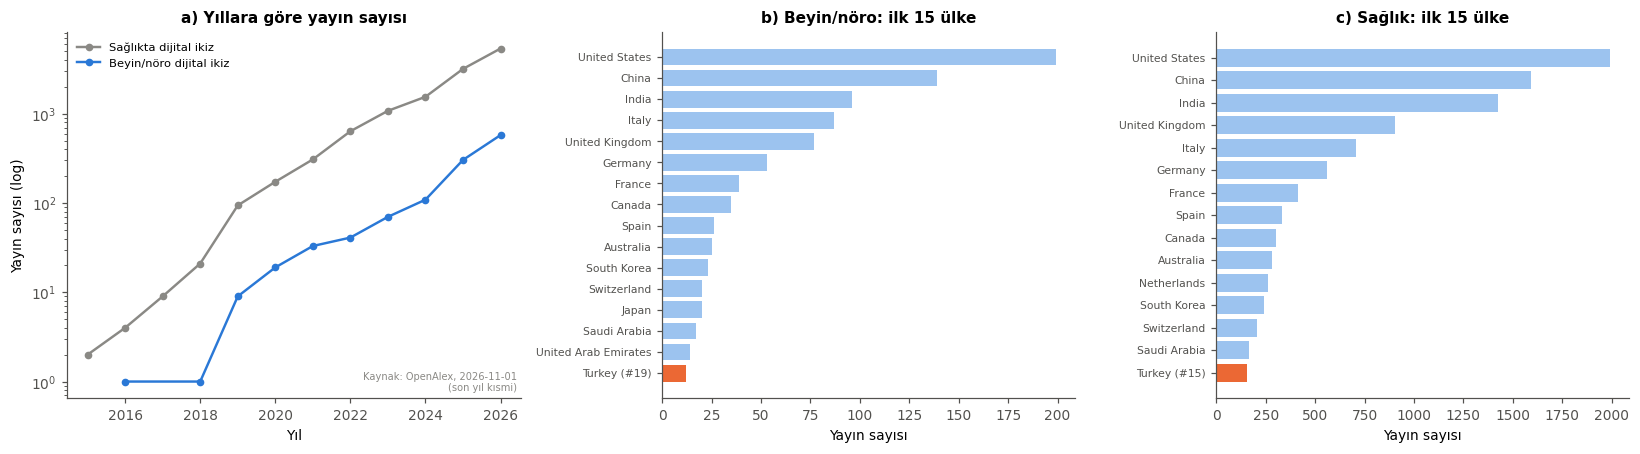

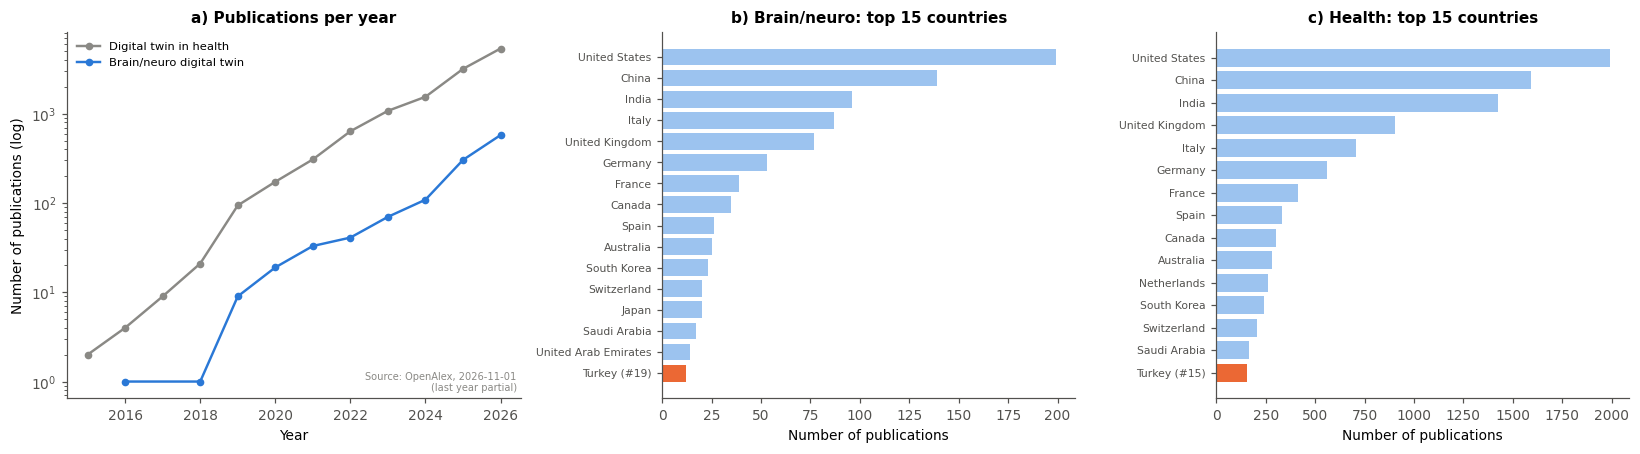

Kaydedildi -> sekiller/tr/sekil15_bibliyometri.jpg  ve  sekiller/en/sekil15_bibliyometri.jpg


In [30]:
# ŞEKİL 15: Bibliyometri
if BIB_OK:
    def ciz(dil):
        fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.1, 1, 1]})
        for df, renk, lab in [(yil_saglik, GRI, T(dil, "Sağlıkta dijital ikiz", "Digital twin in health")),
                              (yil_noro, MAVI, T(dil, "Beyin/nöro dijital ikiz", "Brain/neuro digital twin"))]:
            d = df.assign(yil=df["key"].astype(int)).sort_values("yil")
            ax[0].plot(d["yil"], d["count"], color=renk, marker="o", ms=4, label=lab)
        ax[0].set_yscale("log"); ax[0].set_xlabel(T(dil, "Yıl", "Year"))
        ax[0].set_ylabel(T(dil, "Yayın sayısı (log)", "Number of publications (log)"))
        ax[0].set_title(T(dil, "a) Yıllara göre yayın sayısı", "a) Publications per year"))
        ax[0].legend(fontsize=7.5)
        ax[0].text(0.99, 0.02, T(dil, f"Kaynak: OpenAlex, {BUGUN}\n(son yıl kısmi)",
                                      f"Source: OpenAlex, {BUGUN}\n(last year partial)"),
                   transform=ax[0].transAxes, ha="right", fontsize=6.5, color=GRI)
        for a, U, ttl in [(ax[1], U_NORO, T(dil, "b) Beyin/nöro: ilk 15 ülke", "b) Brain/neuro: top 15 countries")),
                          (ax[2], U_SAGLIK, T(dil, "c) Sağlık: ilk 15 ülke", "c) Health: top 15 countries"))]:
            top = U.head(15).copy()
            if "TR" not in set(top["kod"]) and (U["kod"] == "TR").any():
                top = pd.concat([top, U[U["kod"] == "TR"]])
            top = top.iloc[::-1]
            renk = [TURUNCU if k == "TR" else "#9cc3ef" for k in top["kod"]]
            etiket = [f"{u} (#{s})" if k == "TR" else u for u, k, s in zip(top["Ülke"], top["kod"], top["Sıra"])]
            a.barh(etiket, top["Yayın"], color=renk)
            a.set_xlabel(T(dil, "Yayın sayısı", "Number of publications")); a.set_title(ttl)
            a.tick_params(axis="y", labelsize=7)
        fig.tight_layout()
        return fig
    iki_dilli(ciz, "sekil15_bibliyometri")

In [31]:
# Türkiye adresli beyin/nöro dijital ikiz yayınlarının listesi (derleme bölümü için ham liste)
if BIB_OK:
    js = openalex(f"title_and_abstract.search:{SORGU_NORO},publication_year:2015-2026,authorships.institutions.country_code:TR",
                  per_page=200)
    TR_LISTE = pd.DataFrame([{
        "Yıl": w.get("publication_year"),
        "Başlık": w.get("display_name"),
        "Kaynak": ((w.get("primary_location") or {}).get("source") or {}).get("display_name"),
        "Atıf": w.get("cited_by_count"),
        "DOI": w.get("doi"),
    } for w in js["results"]]).sort_values(["Yıl", "Atıf"], ascending=[False, False])
    TR_LISTE.to_csv(f"ciktilar/openalex_turkiye_liste_{BUGUN}.csv", index=False)
    print(f"{len(TR_LISTE)} kayıt. Not: bu liste anahtar kelime eşleşmesidir; makaleye almadan önce her kayıt elle kontrol edilmeli.")
    display(TR_LISTE.head(25))

12 kayıt. Not: bu liste anahtar kelime eşleşmesidir; makaleye almadan önce her kayıt elle kontrol edilmeli.


,Yıl,Başlık,Kaynak,Atıf,DOI
7,2026,Digital Twins for a Rapidly Fatal Amoebic Infe...,Current Clinical Microbiology Reports,1,https://doi.org/10.1007/s40588-026-00266-3
1,2026,A digital twin for Escherichia coli K1 neonata...,Journal of Medical Microbiology,0,https://doi.org/10.1099/jmm.0.002143
2,2026,The Role of Digital Twins in Clinical Trials: ...,Therapeutic Innovation & Regulatory Science,0,https://doi.org/10.1007/s43441-026-01067-y
5,2026,Digital twin frameworks for polio and post-pol...,Neurological Sciences,0,https://doi.org/10.1007/s10072-025-08777-5
6,2026,A Closed-Loop Cyber-Neurological Framework: De...,Zenodo (CERN European Organization for Nuclear...,0,https://doi.org/10.5281/zenodo.20364878
10,2026,“Integration of Embedded AI and Medical Heat P...,Biomedical Journal of Scientific & Technical R...,0,https://doi.org/10.26717/bjstr.2026.67.010442
11,2026,Süper Akıllı Toplum; Dijital Kimlikler ve Kova...,DOAJ (DOAJ: Directory of Open Access Journals),0,https://doi.org/10.5281/zenodo.19483678
8,2025,Statistical Learning for Personalized Predicti...,Wiley Interdisciplinary Reviews Computational ...,10,https://doi.org/10.1002/wics.70043
0,2025,Applications of Digital Twin in Precision Medi...,International Conference on New Trends in Comp...,6,https://doi.org/10.1109/ictcs65341.2025.10989480
4,2022,DTWN: Q-learning-based Transmit Power Control ...,EAI Endorsed Transactions on Industrial Networ...,8,https://doi.org/10.4108/eetinis.v9i31.1059


In [32]:
# Sorgu kesinliği (precision): bulunan kayıtların başlık/özetinde gerçekten nöro terim geçiyor mu?
NORO_RE = re.compile(r"\b(brain|neuro\w*|neurolog\w*|EEG|fMRI|connectom\w*|epilep\w*|alzheimer\w*|"
                     r"parkinson\w*|multiple sclerosis|stroke|cortex|cortical|neuron\w*)\b", re.I)
YAPAY_RE = re.compile(r"\bneural network", re.I)

def ozet_metni(w):
    # OpenAlex özetleri "ters indeks" biçiminde saklar; düz metne çeviriyoruz.
    inv = w.get("abstract_inverted_index") or {}
    pos = {p: k for k, ps in inv.items() for p in ps}
    return " ".join(pos[i] for i in sorted(pos))

def kesinlik(filtre, n=200):
    js = openalex(filtre, per_page=n)
    rows = []
    for w in js["results"]:
        metin = (w.get("display_name") or "") + " " + ozet_metni(w)
        temiz = YAPAY_RE.sub("", metin)            # "neural network" ifadesini dışarıda bırak
        rows.append({"Yıl": w.get("publication_year"), "Başlık": w.get("display_name"),
                     "Nöro terim var mı": bool(NORO_RE.search(temiz))})
    return pd.DataFrame(rows)

if BIB_OK:
    f_genel = f"title_and_abstract.search:{SORGU_NORO},publication_year:2015-2026"
    K_GENEL = kesinlik(f_genel)
    K_TR = kesinlik(f_genel + ",authorships.institutions.country_code:TR")
    print(f"Küresel örneklem (n={len(K_GENEL)}): kesinlik = %{100*K_GENEL['Nöro terim var mı'].mean():.0f}")
    print(f"Türkiye (n={len(K_TR)}): kesinlik = %{100*K_TR['Nöro terim var mı'].mean():.0f}")
    K_TR.to_csv(f"ciktilar/openalex_turkiye_kesinlik_{BUGUN}.csv", index=False)
    pd.set_option("display.max_colwidth", 120)
    display(K_TR)

Küresel örneklem (n=200): kesinlik = %96
Türkiye (n=12): kesinlik = %83


,Yıl,Başlık,Nöro terim var mı
0,2025,Applications of Digital Twin in Precision Medicine: A Systematic Review,True
1,2026,A digital twin for Escherichia coli K1 neonatal meningitis,True
2,2026,The Role of Digital Twins in Clinical Trials: A New Perspective on Methodological and Statistical Challenges,False
3,2020,Development and Verification of a Digital Twin Patient Model to Predict Specific Treatment Response During the First...,True
4,2022,DTWN: Q-learning-based Transmit Power Control for Digital Twin WiFi Networks,True
5,2026,"Digital twin frameworks for polio and post-polio neurodegeneration: Toward predictive, personalised lifelong neuro-r...",True
6,2026,A Closed-Loop Cyber-Neurological Framework: Deriving Synaptic Network Patterns from Digital Traces for Non-Invasive ...,True
7,2026,Digital Twins for a Rapidly Fatal Amoebic Infection: Modelling Host-Pathogen Dynamics in Primary Amoebic Meningoence...,False
8,2025,"Statistical Learning for Personalized Prediction of Alzheimer's Disease Progression: A Survey of Methods, Data Chall...",True
9,2022,Recent Advances in Cognitive Informatics and Cognitive Computing towards Autonomous Systems (Plenary Panel Report-II...,True


**Elle tarama sonucu (1 Kasım 2026 verisi):** Türkiye adresli 12 kaydın başlık ve özetleri tek tek okundu:
- **Doğrudan sinir sistemi odaklı (5):** polio sonrası nörodejenerasyon ikizi, Alzheimer ilerleme tahmini, robotik nöroşirürji, iki merkezi sinir sistemi enfeksiyonu modeli.
- **Konu dışı (7):** klinik çalışma metodolojisi, sepsis, genel hassas tıp derlemesi, WiFi ağları, bilişsel bilişim paneli, sosyoloji yazısı, hakemsiz bir ön-yükleme.
- **Mekanistik tüm-beyin ağı ikizi: 0.**

Bu sonuç, Türkiye literatüründe kişiye kalibre edilmiş dinamik beyin ağı ikizinin bulunmadığını gerçek veriyle gösteriyor.

### 9.1 Seçilmiş literatür tablosu (elle doğrulanmış kaynaklar)

Aşağıdaki tablo makalenin giriş ve tartışma bölümlerinde kullanılacak temel kaynakları **ikiz türüne** göre sınıflandırıyor. Türkiye'den örnekler ayrıca işaretlendi.

Haber kaynaklı girişler (Hacettepe, OMÜ) **gri literatürdür**. Bu çalışmaların hakemli yayınları çıktığında tabloda onlarla değiştirilmeli.

In [33]:
LIT = pd.DataFrame([
    # (Yazar/Kurum, Yıl, Çalışma, İkiz türü, Veri, Türkiye?)
    ("Deco ve ark.", 2017, "Hopf tüm-beyin modeli; metastabilite ve dinamik çekirdek (Sci Rep)", "Mekanistik / dinamik", "DTI + rs-fMRI", "Hayır"),
    ("Sanz Leon ve ark.", 2013, "The Virtual Brain simülasyon platformu (Front Neuroinform)", "Mekanistik / dinamik", "DTI + EEG/fMRI", "Hayır"),
    ("Cakan, Jajcay & Obermayer", 2021, "neurolib: tüm-beyin modelleme çerçevesi (Cogn Comput)", "Mekanistik / araç", "HCP DTI + rs-fMRI", "Hayır*"),
    ("Xiong ve ark.", 2023, "Digital twin brain: biyolojik ve yapay zekâ arasında köprü (Intell Comput)", "Kavramsal derleme", "—", "Hayır"),
    ("Hashemi ve ark.", 2025, "Principles and operation of virtual brain twins (IEEE Rev Biomed Eng)", "Mekanistik + Bayesçi çıkarım", "MRI, SEEG, MEG", "Hayır"),
    ("Tudor ve ark.", 2025, "Sağlıkta insan dijital ikizleri: kapsam derlemesi (npj Digit Med)", "Sistematik derleme", "149 çalışma", "Hayır"),
    ("Zimmermann ve ark.", 2019, "Bireysel SC–FC ilişkisinin özgüllüğü (Netw Neurosci)", "Bireysellik (ampirik)", "DTI + rs-fMRI", "Hayır"),
    ("Finn ve ark.", 2015, "Fonksiyonel bağlantıom parmak izi (Nat Neurosci)", "Bireysellik (ampirik)", "HCP rs-fMRI", "Hayır"),
    ("Ünal & Toraman", 2023, "Dijital ikiz teknolojisinin değerlendirilmesi (SDÜ Sağlık Yönetimi Dergisi)", "Kavramsal derleme (sağlık)", "—", "Evet"),
    ("Hacettepe Üniv. HÜNERİM", 2026, "Persanavi: MR/BT'den 3B kişiye özel beyin modeli (AA haberi)", "Anatomik / görüntü tabanlı", "MR, BT", "Evet (gri lit.)"),
    ("Ondokuz Mayıs Üniv.", 2026, "MR, EEG, ses, yürüme verisiyle 'sanal hasta' (AA haberi)", "Veri güdümlü / yapay zekâ", "MR, EEG, EMG, ses, video", "Evet (gri lit.)"),
    ("Bu çalışma", 2026, "Kişiye kalibre Hopf ikizi + özgüllük testi + sanal lezyon", "Mekanistik / dinamik", "HCP DTI + rs-fMRI", "Evet"),
], columns=["Yazar / Kurum", "Yıl", "Çalışma", "İkiz türü", "Veri", "Türkiye"])
LIT.to_csv("ciktilar/tablo6_literatur.csv", index=False)
LIT

,Yazar / Kurum,Yıl,Çalışma,İkiz türü,Veri,Türkiye
0,Deco ve ark.,2017,Hopf tüm-beyin modeli; metastabilite ve dinamik çekirdek (Sci Rep),Mekanistik / dinamik,DTI + rs-fMRI,Hayır
1,Sanz Leon ve ark.,2013,The Virtual Brain simülasyon platformu (Front Neuroinform),Mekanistik / dinamik,DTI + EEG/fMRI,Hayır
2,"Cakan, Jajcay & Obermayer",2021,neurolib: tüm-beyin modelleme çerçevesi (Cogn Comput),Mekanistik / araç,HCP DTI + rs-fMRI,Hayır*
3,Xiong ve ark.,2023,Digital twin brain: biyolojik ve yapay zekâ arasında köprü (Intell Comput),Kavramsal derleme,—,Hayır
4,Hashemi ve ark.,2025,Principles and operation of virtual brain twins (IEEE Rev Biomed Eng),Mekanistik + Bayesçi çıkarım,"MRI, SEEG, MEG",Hayır
5,Tudor ve ark.,2025,Sağlıkta insan dijital ikizleri: kapsam derlemesi (npj Digit Med),Sistematik derleme,149 çalışma,Hayır
6,Zimmermann ve ark.,2019,Bireysel SC–FC ilişkisinin özgüllüğü (Netw Neurosci),Bireysellik (ampirik),DTI + rs-fMRI,Hayır
7,Finn ve ark.,2015,Fonksiyonel bağlantıom parmak izi (Nat Neurosci),Bireysellik (ampirik),HCP rs-fMRI,Hayır
8,Ünal & Toraman,2023,Dijital ikiz teknolojisinin değerlendirilmesi (SDÜ Sağlık Yönetimi Dergisi),Kavramsal derleme (sağlık),—,Evet
9,Hacettepe Üniv. HÜNERİM,2026,Persanavi: MR/BT'den 3B kişiye özel beyin modeli (AA haberi),Anatomik / görüntü tabanlı,"MR, BT",Evet (gri lit.)


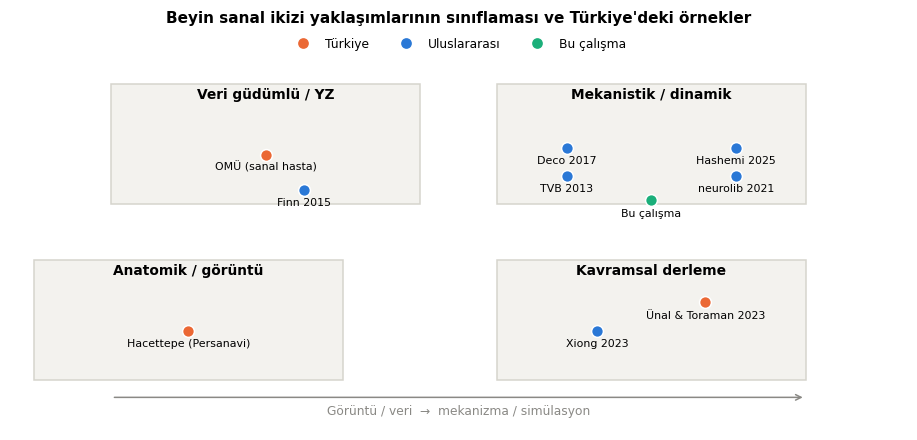

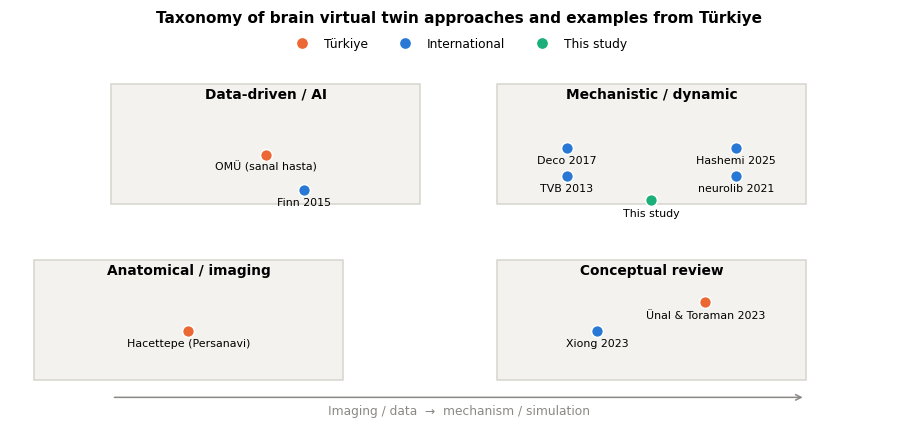

Kaydedildi -> sekiller/tr/sekil16_ikiz_turleri.jpg  ve  sekiller/en/sekil16_ikiz_turleri.jpg


In [34]:
# ŞEKİL 16: İkiz türleri haritası (kavramsal sınıflama, literatür tablosundan)
def ciz(dil):
    fig, ax = plt.subplots(figsize=(10.5, 4.4))
    turler = {
        T(dil, "Anatomik / görüntü", "Anatomical / imaging"): (0.15, 0.25),
        T(dil, "Veri güdümlü / YZ", "Data-driven / AI"): (0.25, 0.75),
        T(dil, "Mekanistik / dinamik", "Mechanistic / dynamic"): (0.75, 0.75),
        T(dil, "Kavramsal derleme", "Conceptual review"): (0.75, 0.25),
    }
    for ad, (x, y) in turler.items():
        ax.add_patch(plt.Rectangle((x - 0.2, y - 0.17), 0.4, 0.34, fc="#f3f2ee", ec="#d6d4cd", lw=1))
        ax.text(x, y + 0.13, ad, ha="center", fontweight="bold", fontsize=9)
    yer = {
        "Hacettepe (Persanavi)": (0.15, 0.22, TURUNCU), "OMÜ (sanal hasta)": (0.25, 0.72, TURUNCU),
        "Deco 2017": (0.64, 0.74, MAVI), "TVB 2013": (0.64, 0.66, MAVI), "Hashemi 2025": (0.86, 0.74, MAVI),
        "neurolib 2021": (0.86, 0.66, MAVI), T(dil, "Bu çalışma", "This study"): (0.75, 0.59, YESIL),
        "Xiong 2023": (0.68, 0.22, MAVI), "Ünal & Toraman 2023": (0.82, 0.30, TURUNCU),
        "Finn 2015": (0.30, 0.62, MAVI),
    }
    for ad, (x, y, renk) in yer.items():
        ax.scatter(x, y, s=60, color=renk, edgecolor="white", zorder=3)
        ax.text(x, y - 0.045, ad, ha="center", fontsize=7.2)
    ax.annotate("", xy=(0.95, 0.03), xytext=(0.05, 0.03), arrowprops=dict(arrowstyle="->", color=GRI))
    ax.text(0.5, -0.02, T(dil, "Görüntü / veri  →  mekanizma / simülasyon", "Imaging / data  →  mechanism / simulation"),
            ha="center", fontsize=8, color=GRI)
    ax.legend(handles=[Line2D([], [], marker="o", ls="", color=TURUNCU, label=T(dil, "Türkiye", "Türkiye")),
                       Line2D([], [], marker="o", ls="", color=MAVI, label=T(dil, "Uluslararası", "International")),
                       Line2D([], [], marker="o", ls="", color=YESIL, label=T(dil, "Bu çalışma", "This study"))],
              loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.08), fontsize=8)
    ax.set_xlim(-0.08, 1.08); ax.set_ylim(-0.06, 1.0); ax.axis("off")
    ax.set_title(T(dil, "Beyin sanal ikizi yaklaşımlarının sınıflaması ve Türkiye'deki örnekler",
                        "Taxonomy of brain virtual twin approaches and examples from Türkiye"), pad=22)
    return fig
iki_dilli(ciz, "sekil16_ikiz_turleri")

## 10. Sonuç tablosu ve şekillerin indirilmesi

In [35]:
SONUC = pd.DataFrame([
    ("Denek sayısı (HCP)", f"{NS}"),
    ("Bölge sayısı (AAL2, kortikal)", f"{N}"),
    ("Doğrudan SC–FC r (ort. ± SS)", f"{np.mean(SCFC_HCP):.3f} ± {np.std(SCFC_HCP):.3f}"),
    ("Sanal ikiz–gerçek FC r (ort. ± SS)", f"{UYUM_EN_IYI.mean():.3f} ± {UYUM_EN_IYI.std():.3f}"),
    ("Kalibre G* aralığı", f"{G_EN_IYI.min()} – {G_EN_IYI.max()}"),
    ("FCD KS mesafesi (ort.)", f"{np.mean(FCD_KS):.3f}"),
    ("Çapraz doğrulama test r (ort.)", f"{CV['Test r (2. yarı)'].mean():.3f}"),
    ("Test-tekrar tavanı r (ort.)", f"{CV['Tavan r (1. yarı ↔ 2. yarı)'].mean():.3f}"),
    ("Kimliklendirme doğruluğu", f"%{dogru_kimlik*100:.0f} (şans %{100/NS:.0f})"),
    ("Kişiselleştirme kazancı Δr (perm. p)", f"{kazanc:.4f} (p = {p_perm:.3f})"),
    ("Grup ortalaması ikizi r (ort.)", f"{grup_uyum.mean():.3f}"),
    ("Kendi SC + grup ω ikizi r (ort.)", f"{kendiSC_grupW.mean():.3f}"),
    ("Grup SC + kendi ω ikizi r (ort.)", f"{grupSC_kendiW.mean():.3f}"),
    ("Karıştırılmış ağ ikizi r (ort.)", f"{karis_uyum.mean():.3f}"),
    ("Lezyon haritası güvenilirliği A–B ρ (ort.)", f"{GUVENILIRLIK.mean():.3f}"),
    ("Lezyon bozulması–düğüm gücü Spearman ρ", f"{rho:.3f} (p = {p_rho:.1e})"),
    ("Lezyon profili denekler arası ρ (ort.)", f"{R_LEZ[~np.eye(NS, dtype=bool)].mean():.3f}"),
], columns=["Ölçü", "Değer"])
SONUC.to_csv("ciktilar/tablo0_ana_sonuclar.csv", index=False)
SONUC

,Ölçü,Değer
0,Denek sayısı (HCP),7
1,"Bölge sayısı (AAL2, kortikal)",80
2,Doğrudan SC–FC r (ort. ± SS),0.263 ± 0.042
3,Sanal ikiz–gerçek FC r (ort. ± SS),0.471 ± 0.115
4,Kalibre G* aralığı,0.15 – 0.45
5,FCD KS mesafesi (ort.),0.459
6,Çapraz doğrulama test r (ort.),0.455
7,Test-tekrar tavanı r (ort.),0.682
8,Kimliklendirme doğruluğu,%14 (şans %14)
9,Kişiselleştirme kazancı Δr (perm. p),-0.0074 (p = 0.784)


In [36]:
# Tüm şekilleri ve tabloları tek bir zip dosyasında topla
ZIP_AD = "sanal_ikiz_ciktilar.zip"
with zipfile.ZipFile(ZIP_AD, "w", zipfile.ZIP_DEFLATED) as z:
    for kok in [SEKIL_DIR, "ciktilar"]:
        for d, _, dosyalar in os.walk(kok):
            for f in dosyalar:
                z.write(os.path.join(d, f))
print("Oluşturuldu:", ZIP_AD, f"({os.path.getsize(ZIP_AD)/1e6:.1f} MB)")
print("Türkçe şekiller:", len(os.listdir(os.path.join(SEKIL_DIR, 'tr'))),
      "| İngilizce şekiller:", len(os.listdir(os.path.join(SEKIL_DIR, 'en'))))

# Colab'daysak dosyayı otomatik indir
try:
    from google.colab import files
    files.download(ZIP_AD)
except ImportError:
    print("Colab dışında çalışıyorsunuz; zip dosyası çalışma klasöründe.")

Oluşturuldu: sanal_ikiz_ciktilar.zip (14.6 MB)
Türkçe şekiller: 16 | İngilizce şekiller: 16


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Sonuçlar ve makale için özet

> Aşağıdaki sayılar Google Colab'da yapılan çalıştırmadan (1 Kasım 2026) alındı ve makalede bu değerler kullanıldı. Tüm rastgele süreçler sabit tohumla başladığı için aynı ortamda aynı değerler elde edilir. Farklı kütüphane sürümlerinde yalnızca son basamaklar değişebilir.

### Bulgular

| # | Bulgu | Sayısal sonuç |
|---|-------|---------------|
| 1 | Sanal ikiz, yapıdan doğrudan tahminin çok üzerinde | İkiz r = 0,471 ± 0,115 ve doğrudan SC–FC r = 0,263 ± 0,042; ikiz 7 deneğin 7'sinde daha iyi (Wilcoxon p = 0,016) |
| 2 | İkiz görmediği veriyi öngörüyor | Test r = 0,455; test-tekrar tavanının (r = 0,682) ortalama %69'u |
| 3 | Zamansal dinamik kısmen yakalanıyor | FCD KS = 0,46 (0,20–0,57); kalibrasyonda kullanılmayan bağımsız bir ölçü |
| 4 | Yapının düzeni belirleyici | Karıştırılmış ağ ikizi r = 0,065; kendi ikizi ile fark +0,41 (p = 0,016) |
| 5 | Bireysel yapı avantaj sağlamıyor | Kimliklendirme %14 (şans %14); Δr = −0,007, permütasyon p = 0,78. Grup ortalaması ikizi r = 0,495 |
| 6 | Sanal lezyon: hub'lar kritik | Bozulma–düğüm gücü ρ = 0,79 (p < 10⁻¹⁷); en etkili bölgeler orta/üst temporal ve frontal hub'lar |
| 7 | Lezyon haritaları güvenilir ama bireysel değil | Tohum setleri arası güvenilirlik ρ = 0,85; denekler arası benzerlik ρ = 0,81 |
| 8 | Bibliyometri | 1.164 beyin/nöro dijital ikiz yayını (kesinlik %96); Türkiye 12 yayınla 19. sırada; elle taramada 5 ilgili, 0 mekanistik beyin ağı ikizi |

### Makalenin ana mesajı (tartışma için)

Kişinin kendi DTI bağlantıomu ve kendi bölgesel ritimleriyle kalibre edilen bir Hopf tüm-beyin modeli, dinlenim-hali beyin aktivitesini yapının tek başına açıklayabildiğinin neredeyse iki katı düzeyinde yeniden üretiyor. Model görmediği veriye de genelleniyor. Ancak bu başarı **kişiye özgü değil**: aynı model, başka bir kişinin ya da grubun bağlantıomuyla kurulduğunda da aynı düzeyde başarılı. Yani bu veride "ikiz" bireyin değil, **insan beyninin ortak bağlantı mimarisinin** ikizi.

Bu sonuç, dijital ikiz literatüründeki kişiselleştirme iddialarının sistematik olarak test edilmesi gerektiğine somut bir örnek oluşturuyor. Literatürde incelenen çalışmaların çok azının kişiselleştirme, güncelleme ve öngörü kriterlerini birlikte karşıladığı bildirilmişti.

**Türkiye bağlamında:** Türkiye'deki örnekler iki farklı yaklaşımda yoğunlaşıyor: anatomik/görüntü tabanlı ikiz (Hacettepe, Persanavi) ve veri güdümlü/yapay zekâ ikizi (OMÜ). Mekanistik, kişiye kalibre edilmiş dinamik beyin ağı ikizi Türkiye literatüründe görece boş bir alan. Bu çalışma o boşluğa açık veri ve açık kodla yanıt veriyor. Bölüm 9'daki OpenAlex analizi bu boşluğu nicel olarak gösterecek.

### Kısıtlılıklar (makalede açıkça yazılmalı)
- **Küçük örneklem:** 7 HCP deneği var. İstatistiksel güç düşük; Wilcoxon testinin n = 7'de ulaşabileceği en küçük p değeri 0,016. Bulgular kavram kanıtı niteliğinde. Daha büyük HCP örneklemiyle tekrar edilmesi gerekiyor.
- **Tek oturum:** Her denek için tek bir 14,4 dakikalık dinlenim kaydı var. Bireysel imza, birden fazla oturumla daha güvenilir ölçülür.
- **Basit model:** Tek serbest parametre (G) kullanıldı. İletim gecikmeleri, bölgesel heterojenlik ve hemodinamik model dahil edilmedi.
- **Atlas:** AAL2 ile 80 kortikal bölge kullanıldı; alt-kortikal yapılar dışarıda kaldı.
- **Sağlıklı denekler:** Lezyon deneyleri sanal. Klinik geçerlilik için gerçek hasta verisi gerekiyor.

### Kaynaklar (doğrulanmış)
1. Cakan C, Jajcay N, Obermayer K (2021). neurolib: A simulation framework for whole-brain neural mass modeling. *Cognitive Computation*.
2. Deco G, Kringelbach ML, Jirsa VK, Ritter P (2017). The dynamics of resting fluctuations in the brain: metastability and its dynamical cortical core. *Scientific Reports*, 7, 3095.
3. Finn ES ve ark. (2015). Functional connectome fingerprinting. *Nature Neuroscience*, 18, 1664–1671.
4. Hansen ECA, Battaglia D, Spiegler A, Deco G, Jirsa VK (2015). Functional connectivity dynamics: modeling the switching behavior of the resting state. *NeuroImage*, 105, 525–535.
5. Sanz Leon P ve ark. (2013). The Virtual Brain: a simulator of primate brain network dynamics. *Frontiers in Neuroinformatics*, 7, 10.
6. Van Essen DC ve ark. (2013). The WU-Minn Human Connectome Project: an overview. *NeuroImage*, 80, 62–79.
7. Hashemi M ve ark. (2026). Principles and operation of virtual brain twins. *IEEE Reviews in Biomedical Engineering*, 19, 111–139.
8. Xiong H ve ark. (2023). Digital twin brain: a bridge between biological intelligence and artificial intelligence. *Intelligent Computing*, 2, 0055.
9. Zimmermann J, Griffiths J, Schirner M, Ritter P, McIntosh AR (2019). Subject specificity of the correlation between large-scale structural and functional connectivity. *Network Neuroscience*, 3(1), 90–106.
10. Rolls ET, Joliot M, Tzourio-Mazoyer N (2015). Implementation of a new parcellation of the orbitofrontal cortex in the automated anatomical labeling atlas. *NeuroImage*, 122, 1–5.
11. Priem J, Piwowar H, Orr R (2022). OpenAlex: A fully-open index of scholarly works, authors, venues, institutions, and concepts. *arXiv:2205.01833*.
12. Ünal AK, Toraman A (2023). Evaluation of digital twin technology. *SDÜ Sağlık Yönetimi Dergisi*, 5, 1–25.
13. Anadolu Ajansı (2026). Beyin ameliyatları yerli "dijital ikiz" teknolojisiyle kişiye özel planlanıyor (Hacettepe, Persanavi). Gri literatür.
14. Anadolu Ajansı (2026). Nörolojik hastalıklarda "dijital ikiz" yöntemiyle kişiye özel tedavi yapılacak (OMÜ). Gri literatür.

> JCBCM kaynak biçimi: metinde [1], [2] şeklinde, metinde geçiş sırasıyla numaralanır; DOI gösterilmez. Makaleye aktarırken bu sırayı metin akışına göre yeniden düzenleyin.